# 가설 2 추가검증 — 겉모습인가, 주제인가

**질문**: 모델이 "실제 글이 붙으면 혐오"로 판단하는 이유는 글의 겉모습인가, 주제(혐오 대상)인가?

기존 `project_h2.ipynb`에서는 무관한 글이라도 실제 글이면 약 75%를 혐오로 판정했다. 새로 쓴 글은 겉모습과 주제가 함께 달라 원인을 가를 수 없었다. 여기서는 주제를 맞춘 뒤 다시 잰다.

**용어**
- 실제 글: 데이터셋에 원래 있던 게시글 (Type 1·3)
- 새로 쓴 글: 같은 댓글이 비혐오로 읽히도록 새로 쓴 게시글 (Type 2)
- 같은 대상 / 다른 대상: 글 주제에 댓글이 겨냥한 대상이 들어 있음 / 없음

**비교** (댓글은 그대로, 글만 바꿈)
| 효과 | 계산 | 크면 |
|---|---|---|
| 주제 효과 | 같은 대상 실제 − 다른 대상 실제 | 모델이 주제를 본다 |
| 겉모습 효과 | 같은 대상 실제 − 같은 대상 새로 씀 | 모델이 실제 글인지를 본다 |
| 재현 확인 | 다른 대상 실제 − 다른 대상 새로 씀 | 기존 결과가 다시 나온다 |

**결정사항**: 학습 seed 42 하나 · 혐오 판정은 확률 > 0.5 · 글 주제는 Claude가 판단

**순서**: 1 글 주제 표시 → 2 후보 수 → 3 판정 기준 → 4 학습 → 5 분석 → 6 사후 분석 → 7·8 다른 모델 확인(KLUE, mBERT) → 9 결론

| 결과 파일 | 내용 |
|---|---|
| `results/h2_context_topics.csv` | 글 282개의 주제 |
| `results/h2_swap_candidates.csv` | fold·대상별 후보 수 |
| `results/plm_h2_topic_preds.csv`, `plm_h2_topic.csv` | 세 모델의 행별 점수, 학습 기록 (`model` 열로 구분) |
| `results/h2_claude_label_compare.csv` | Claude 판정과 데이터셋 정답·세 모델 예측 비교 (6절) |
| `figures/project_h2_plus_*.png` | 그림 3장 |

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path('..').resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = Path('.').resolve()  # repo 루트에서 실행하는 경우
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import preprocess as pp

SEED = pp.SEED
TOPICS_PATH = PROJECT_ROOT / 'results' / 'h2_context_topics.csv'
SAMPLE_PATH = PROJECT_ROOT / 'data' / 'h2_topic_check_r3.csv'   # 최종(3차) 검증 샘플

TARGETS = ['Gender', 'Disability', 'Race/Nationality', 'Region (Korea)', 'Age']
KO = {'Gender': '성별', 'Disability': '장애', 'Race/Nationality': '인종·국적', 'Region (Korea)': '지역', 'Age': '연령'}
EN = {v: k for k, v in KO.items()}
N_SAMPLE = {'실제': 15, '새로 씀': 15}
PASS_N = 27   # 30개 중 27개(90%) 이상 일치하면 Claude 표시를 사용

raw = pd.read_csv(pp.DATA_PATH)
raw = raw.assign(post_group=pp.make_post_groups(raw))
print(f"seed = {SEED}, 데이터 {len(raw)}행, post_group {raw['post_group'].nunique()}개")

seed = 42, 데이터 3000행, post_group 77개


---
## 1. 글 주제 표시
데이터셋의 대상 라벨은 **댓글**이 겨냥한 대상이라 글 주제와 다르다(1-3). 그래서 글 282개의 주제를 새로 표시한다.

### 1-1. 판단 기준 — 중심 대상
글(Context) 문장만 읽고, **글이 무엇에 관한 글인지 한 줄로 요약했을 때 핵심으로 남는 집단·장소**만 표시한다. 글이 혐오적인지는 따지지 않는다. 1차 검증(1-4)에서 "언급된 집단을 모두 표시"하는 기준은 사람 판단과 70%만 일치해 이 기준으로 바꿨다.

| 범주 | 해당 (중심일 때) | 예 |
|---|---|---|
| 성별 | 성별 집단이나 성별 쟁점이 논점(여성 고용, 페미니즘, 성범죄, 출산, 성별 임금 격차 등) | "여성 고용이 미흡해…" → 성별 |
| 장애 | 장애·장애인, 치매 등이 논점 | "…어머니가 알츠하이머로 의심되는 증상" → 장애 |
| 인종·국적 | 인종·국적·민족·종교 집단이 논점, 또는 **국외 국가·지역 자체가 소재**(그곳의 사건·장소·문화) | "일본 도쿄에서 지진이 발생했다" → 인종·국적 |
| 지역 | **국내 지역 자체가 소재**(그곳의 사건·장소·음식), 출신 지역·방언·지역 감정 | "대구의 돼지막창집에서…" → 지역 |
| 연령 | 나이·세대 집단이 논점(노인, 청년, 청소년, 나이 기준 등) | "공공 기관의 청년 열정 페이" → 연령 |

**보완 규칙 (2차 검증 후 추가)**
- 사건이 일어난 **국내 지역이 명시되면 지역에 포함**한다: "경기도 광주시에서 … 성범죄를 저지른 남성에게 … 구형" → 성별, 지역
- 국가·지역명이 없어도 **일반 독자가 바로 알 수 있는 암시**로 글의 중심이 특정 국가·지역이면 포함한다: "이토 히로부미 … 독립운동가" → 인종·국적, "성심당 …" → 지역(대전), "부추를 정구지라고" → 지역(경상도 방언)
- 국외 국가의 사건·문화 자체가 소재이면 인종·국적: "일본에서 올해의 한자로 '금'이 선정" → 인종·국적
- 나이가 정책·논점 자체이면 연령: "난임 … 여성 나이 기준 폐지" → 성별, 연령

**제외 (부수 정보)**
- 인물을 묘사하는 나이·성별·국적: "20대 여성 회사원이 결혼식 날짜를…" → 없음, "전주 제지공장에서 일하던 19세 청년이…" → 지역만
- 다른 논점의 배경일 뿐인 국가: "미국 교수가 남녀 임금 격차는 없다고…" → 성별만
- 요리·양식 이름의 국가·지명(텍사스식 바비큐, 중국 음식점), 특정 지역이 아닌 말(전국, 국내, 동네, 지역 화폐)
- 국외 지명은 '지역'이 아니라 '인종·국적'이다(지역 = 국내만).

### 1-2. Claude 판단표
Claude(claude-opus-5-5)가 글만 읽고 판단해 아래에 고정했다(2026-11-18). 판단자는 1명이고, Type 1 글은 라벨을 본 적이 있는 상태에서 판단했다.

In [2]:
ANNOT = '''
# context_id | 중심 대상(성별/장애/인종·국적/지역/연령, 없으면 -) | 근거
ctx_1|성별|여성 고용 불이익
ctx_29|-|기업 복지
ctx_62|성별,연령|여성 나이 기준 폐지
ctx_73|-|드라마 시청률
ctx_84|인종·국적|흑인 인식 못한 중국 AI
ctx_101|인종·국적|중국 AI
ctx_119|성별,지역|밀양 성폭행 사건
ctx_134|지역|밀양 맛집
ctx_141|지역|광주 방문
ctx_145|지역|밀양 행정 구역
ctx_169|인종·국적|아우슈비츠 유대인
ctx_170|인종·국적|독일 식당
ctx_177|성별|첫 여성 대통령 (멕시코·61세는 배경)
ctx_179|-|동물
ctx_180|-|아파트 용적률
ctx_186|지역|전라도 출신 조폭
ctx_187|지역|전라도 출신 조폭
ctx_188|지역|전라도 출신 조폭
ctx_189|지역|전라도 출신 조폭
ctx_190|지역|전라도 출신 조폭
ctx_191|지역|전라도 출신 조폭
ctx_192|지역|전라도 출신 조폭
ctx_193|지역|전라도 출신 조폭
ctx_194|지역|전라도 출신 조폭
ctx_195|지역|전라도 출신 조폭
ctx_196|-|'전국' 한정식집
ctx_204|-|정당 후보 성씨
ctx_205|-|민주화 운동가 전과
ctx_211|성별|남녀 임금 격차 (미국은 배경)
ctx_215|-|현대 사회 자유 (미국은 배경)
ctx_221|성별,지역|성범죄 구형, 경기도 광주시 사건
ctx_226|지역|지역별 구호
ctx_236|인종·국적|러시아와 한국 비교
ctx_237|인종·국적,지역|러시아인의 서울 맛집 반응
ctx_259|지역|대구 지점 위생 사건
ctx_264|지역|서울·본가(출신 지역)
ctx_281|인종·국적|멕시코 총격 사건
ctx_293|성별|여성 지위 (멕시코는 배경)
ctx_299|인종·국적|멕시코 시위
ctx_302|인종·국적|멕시코시티 한식당
ctx_308|인종·국적|베트남에서 일어난 살인
ctx_329|지역|광주 음식
ctx_337|인종·국적|오사카 음식
ctx_425|인종·국적|흑인 학생 목화 따기
ctx_447|인종·국적|일본군에 맞선 조상
ctx_449|연령|청년 열정 페이
ctx_452|-|전통 체험
ctx_458|인종·국적|히로시마 방문 비판
ctx_460|지역|진주시 문화원 논란
ctx_462|인종·국적|중국 학교 이야기
ctx_477|-|위험한 음식 재료
ctx_538|지역|성심당(대전 암시) 월세 논란
ctx_539|-|설날 만두
ctx_580|성별,지역|밀양 성폭행 사건
ctx_597|지역|지역 감정
ctx_598|지역|밀양 행사
ctx_602|지역|밀양·전남 위치
ctx_642|지역|부산 숙소
ctx_663|지역|신안 천일염
ctx_674|-|알파벳
ctx_742|장애|치매(알츠하이머) 증상
ctx_743|인종·국적|원나라의 고려 문화 유행
ctx_760|지역|전주 사건
ctx_775|지역|전북 출신, 오일팔
ctx_783|지역|대구에서 서울로 전학
ctx_784|-|옛 국가 역사
ctx_785|-|저녁 식사 시간
ctx_788|-|언론 별명
ctx_795|인종·국적|한일 국제 커플
ctx_798|인종·국적|일본 게임
ctx_799|-|요리
ctx_813|성별,지역|부산, 여성 기사 폭행
ctx_815|지역|부산 행정 구역
ctx_816|-|디저트
ctx_824|지역|대구 아파트
ctx_851|성별,지역|여성 대상 교제 폭력, 하남·서울
ctx_858|지역|수원 음주 운전 검거
ctx_869|성별,지역|아줌마 출입 금지, 인천
ctx_903|지역|인천 송도 헬스장 (장애인 할인은 부수)
ctx_905|지역|인천 헬스장
ctx_941|인종·국적|다문화 가정 자녀
ctx_958|지역|충남 학생 선행
ctx_980|지역|부안 지진
ctx_995|인종·국적|도쿄 지진
ctx_1017|인종·국적|흑인 린치
ctx_1053|성별|출산 휴가
ctx_1054|인종·국적|미국 서부 개척 시대
ctx_1062|-|바비큐 요리 (텍사스식은 요리 이름)
ctx_1094|인종·국적|태국에서 일어난 살인
ctx_1096|인종·국적|일본 나가노
ctx_1097|지역|지역별 아리랑
ctx_1099|-|훈련병 의무 기록
ctx_1102|-|데이트 영화
ctx_1111|지역,연령|대구, 80대 노인 송치
ctx_1116|인종·국적|미국인 커플
ctx_1119|지역|대구 막창
ctx_1168|-|결혼식 날짜 (20대 여성은 부수)
ctx_1169|-|돼지국밥
ctx_1215|성별,지역|여성 경찰, 대구 난동
ctx_1221|지역|대구 막창
ctx_1222|-|야구
ctx_1223|지역|목포 식당
ctx_1226|-|아이돌 방송
ctx_1236|인종·국적|유럽인과 원숭이 묘사 논란
ctx_1239|지역|서울 전시회
ctx_1240|-|조선 역사
ctx_1255|성별,인종·국적,연령|무슬림의 여아 결혼·여성 나이 비하
ctx_1292|인종·국적|무슬림 자녀 교육
ctx_1308|지역|밀양 출신 독립운동가
ctx_1338|-|아르바이트생 요구 (여성은 부수)
ctx_1341|-|흙수저 일기 콘텐츠 (한국인 여성은 부수)
ctx_1342|인종·국적|국적 추측
ctx_1343|-|경기장 사진
ctx_1355|-|식당 제안
ctx_1358|성별|성별 맞히기
ctx_1430|인종·국적|일본에서 일어난 살인
ctx_1431|-|한정식
ctx_1436|성별|여성 대상 성폭행
ctx_1440|-|양궁 대표팀 기록 (여자부는 부수)
ctx_1441|-|접촉 사고
ctx_1443|-|숙소
ctx_1448|인종·국적|중국 폭염
ctx_1463|-|해충 장치
ctx_1469|-|캠페인
ctx_1470|인종·국적|몽골 프로젝트
ctx_1471|-|목사
ctx_1476|-|오존층
ctx_1498|인종·국적|블랙워싱
ctx_1499|지역|동해안 식당
ctx_1500|-|번역 표현 논쟁 (일본 소설은 배경)
ctx_1501|-|알파벳
ctx_1502|-|대리기사
ctx_1511|지역|지역 방언
ctx_1528|지역|부산고법 창원재판부 선고
ctx_1540|지역|창원 위치
ctx_1541|지역|창원 노래자랑
ctx_1543|지역|경남 관할 법원
ctx_1544|지역|담양
ctx_1594|성별,인종·국적|벨라루스 처녀와 혼인
ctx_1597|-|동물
ctx_1603|인종·국적|일본·한국·동남아인 반응
ctx_1606|-|동물
ctx_1610|-|멧돼지 피해
ctx_1613|성별|여성 작가 노벨상
ctx_1614|-|연극
ctx_1623|성별|여성 연애 경험 주장
ctx_1638|-|식사권
ctx_1657|성별|연애한 여자 험담
ctx_1669|-|소비
ctx_1682|성별,연령|나이 든 여성 비하어
ctx_1692|-|한글
ctx_1693|-|춤
ctx_1696|인종·국적|일본 올해의 한자
ctx_1703|성별|성추행 판결
ctx_1706|지역,연령|청주, 70대 근로자
ctx_1710|인종·국적,지역|청주 직지, 프랑스 소장
ctx_1711|지역|목포 백반
ctx_1721|성별,연령,지역|40대 이상 독신 남성 피해, 전주
ctx_1728|-|부부 인터뷰
ctx_1729|지역|전주 백반
ctx_1737|인종·국적|흑인 난민
ctx_1740|-|동네 음식
ctx_1741|성별|딥페이크 성범죄
ctx_1744|성별,연령|여성 출산 적령기
ctx_1748|-|드라마 추천
ctx_1752|인종·국적,지역|대구 이슬람 사원
ctx_1764|-|부실 공사
ctx_1777|지역|광주 고깃집
ctx_1800|지역|광주 비빔밥
ctx_1804|인종·국적|중국 업체
ctx_1808|지역|정구지(경상도 방언 암시)
ctx_1811|인종·국적|프랑스 레스토랑
ctx_1835|지역|전주 공장 사고
ctx_1858|지역|유명한 곳(지역 특산)을 물음
ctx_1863|지역|전주 백반
ctx_1875|-|생선
ctx_1983|성별|성별 임금 격차 (미국은 배경)
ctx_1985|-|재단 기부 (미국은 배경)
ctx_1989|성별|여성 CPR 성추행 주장
ctx_1992|지역|혜화 족발
ctx_1997|성별|아내 호칭에 대한 여성들 비난
ctx_1999|-|닭 사육
ctx_2006|성별|폐경·완경
ctx_2008|성별|친구 중 여성은 모두 작가
ctx_2011|성별|동덕여대 시위, 페미니스트
ctx_2012|-|기부
ctx_2015|성별|여성 직원 논쟁
ctx_2020|인종·국적|일본인 독도 발언
ctx_2026|성별|페미니스트 외모
ctx_2027|-|음식
ctx_2028|성별|이화여대생으로 밝혀짐
ctx_2035|성별|이화여대생으로 밝혀짐
ctx_2171|연령|노인 항의
ctx_2174|-|삵 방사
ctx_2182|-|무단횡단
ctx_2189|-|자전거 모임
ctx_2190|지역|수원 정원 (중국식은 양식 이름)
ctx_2192|-|장 담그기 (여성 요리사는 부수)
ctx_2313|인종·국적|베트남 여성과 국제 결혼
ctx_2315|-|아버지 추억
ctx_2334|성별|남성 아이돌 팬의 소녀시대 보이콧
ctx_2335|인종·국적|일본 베스트셀러
ctx_2350|인종·국적|중국 조직
ctx_2354|-|바퀴벌레
ctx_2355|인종·국적|일본어 소설 취미
ctx_2357|인종·국적|일본 코미디언
ctx_2369|인종·국적|중국 우한 폭발
ctx_2386|연령|청소년 보호 처분
ctx_2387|-|백신
ctx_2388|-|교정 교육
ctx_2390|인종·국적|두바이 화재
ctx_2392|-|모기
ctx_2426|인종·국적|중국 건물 사고
ctx_2430|인종·국적|중국인
ctx_2436|인종·국적|중국 바이러스
ctx_2437|-|e스포츠
ctx_2451|인종·국적|티베트 독립·중국인 반응
ctx_2453|-|앞머리
ctx_2459|성별,인종·국적|한국 여성·외국 여성 매매혼
ctx_2462|-|게임 전술
ctx_2475|성별|여성 경찰 능력 (미국은 배경)
ctx_2478|인종·국적|미국 김밥 인기
ctx_2479|인종·국적|미국 한식 유행
ctx_2484|인종·국적|중국인 일본 지하철
ctx_2490|-|올림픽 개최국 질문 (국가명 없음)
ctx_2496|성별|여자어
ctx_2498|성별|성별 맞히기
ctx_2499|-|번역기
ctx_2514|성별|동덕여대 시위 선택 논란
ctx_2541|-|퀴즈
ctx_2574|성별|동덕여대 시위
ctx_2575|-|아이스크림
ctx_2576|성별|여성의 성폭행 시도
ctx_2577|-|맥주
ctx_2580|인종·국적|이민 간 한국계 검사
ctx_2583|인종·국적|이토 히로부미에 맞선 독립운동가(일본 암시)
ctx_2585|-|게시판
ctx_2598|인종·국적|중국 추정 계정
ctx_2601|-|갈비
ctx_2602|-|요리
ctx_2604|지역|전남 무안 경찰
ctx_2607|인종·국적|호주 수도
ctx_2620|-|피규어 처분
ctx_2621|-|운동
ctx_2640|인종·국적|중국 서해 구조물
ctx_2643|-|강아지
ctx_2645|-|음식
ctx_2646|인종·국적|중국인 드론 촬영
ctx_2651|-|지역 화폐 서비스(특정 지역 아님)
ctx_2655|-|요리
ctx_2661|인종·국적|일본 대학 난동
ctx_2663|-|층간 소음
ctx_2664|인종·국적|국적 질문
ctx_2697|인종·국적|일본 난동 유학생
ctx_2698|-|노래
ctx_2709|성별|비동의강간죄
ctx_2711|-|알파벳
ctx_2712|-|약수
ctx_2714|-|다양성 정책(특정 집단 아님)
ctx_2723|인종·국적|미국 경제
ctx_2725|-|국가 유공자
ctx_2732|성별|트랜스젠더 정책
ctx_2743|-|주가
ctx_2745|지역|국립대구박물관
ctx_2746|인종·국적|미국 기업 유치
ctx_2758|인종·국적|중국인 역주행 사고
ctx_2762|-|한자
ctx_2763|-|한문
ctx_2764|-|한자
ctx_2805|성별|페미니즘 후드티
ctx_2811|-|고양이 사진
ctx_2812|-|취업
ctx_2814|-|음식점 (중국 음식은 요리 이름)
ctx_2821|성별,연령|10대 남자의 여성 혐오 단어
ctx_2823|연령|10대 봉사 활동
ctx_2825|성별,연령|10대 남자의 여성 혐오 단어
ctx_2842|성별|두 가지 성별 인정
ctx_2900|성별|두 가지 성별 선언 (미국은 배경)
ctx_2923|-|주가 조작
ctx_2930|인종·국적|미국 주가
ctx_2947|성별|페미 비난 (일본은 배경)
ctx_2970|-|웹툰
'''

rows = []
for line in ANNOT.strip().splitlines():
    if line.startswith('#'):
        continue
    cid, tg, why = [x.strip() for x in line.split('|')]
    names = [] if tg == '-' else tg.split(',')
    assert all(n in EN for n in names), (cid, tg)
    rows.append({'context_id': cid, 'claude_names': names, '근거': why})
claude = pd.DataFrame(rows)
assert claude['context_id'].is_unique

# 고유 Context 정보: context_id = 그 Context가 나오는 행의 최소 Index
info = (raw.groupby('Context')
           .agg(idx=('Index', 'min'), post_group=('post_group', 'first'), n_rows=('Index', 'size'),
                rewritten=('Type', lambda t: bool((t == 2).all())),
                types=('Type', lambda t: '/'.join(str(int(x)) for x in sorted(t.unique()))))
           .reset_index())
info['context_id'] = 'ctx_' + info['idx'].astype(str)
assert set(info['context_id']) == set(claude['context_id']), '판단표와 데이터의 고유 Context가 다름'

topics = info.merge(claude, on='context_id').sort_values('idx').reset_index(drop=True)
topics['구분'] = np.where(topics['rewritten'], '새로 씀', '실제')
for t in TARGETS:
    topics[f'topic_{t}'] = topics['claude_names'].apply(lambda n: int(KO[t] in n))
topics['주제'] = topics['claude_names'].apply(lambda n: ', '.join(KO[t] for t in TARGETS if KO[t] in n) or '없음')
out = topics[['context_id', '구분', 'post_group', 'n_rows', 'types', '주제', '근거'] + [f'topic_{t}' for t in TARGETS]]
out = out.rename(columns={'n_rows': '행 수', 'types': 'Type 구성'})
out.to_csv(TOPICS_PATH, index=False, encoding='utf-8-sig')
print(f"저장: {TOPICS_PATH.relative_to(PROJECT_ROOT)} — 고유 글 {len(out)}개 {out['구분'].value_counts().to_dict()}")

count = pd.DataFrame({k: out.loc[out['구분'] == k, [f'topic_{t}' for t in TARGETS]].sum().to_numpy()
                      for k in ['실제', '새로 씀']}, index=[KO[t] for t in TARGETS])
count.loc['주제 있음(1개 이상)'] = [int((out.loc[out['구분'] == k, '주제'] != '없음').sum()) for k in count.columns]
count.loc['고유 글 수'] = out['구분'].value_counts().reindex(count.columns).to_numpy()
print("[글 주제 — 대상별 고유 글 수 (한 글에 여러 주제 가능)]")
display(count)

저장: results/h2_context_topics.csv — 고유 글 282개 {'새로 씀': 171, '실제': 111}
[글 주제 — 대상별 고유 글 수 (한 글에 여러 주제 가능)]


,실제,새로 씀
성별,43,8
장애,1,0
인종·국적,34,36
지역,33,39
연령,10,3
주제 있음(1개 이상),100,84
고유 글 수,111,171


### 1-3. 라벨과 비교
Type 1 글 110개에서 라벨(댓글 대상)과 글 주제가 얼마나 같은지 본다.

In [3]:
t1 = raw[raw['Type'] == 1].groupby('Context')[TARGETS].max()
t1.index = 'ctx_' + raw[raw['Type'] == 1].groupby('Context')['Index'].min().reindex(t1.index).astype(str)
cmp_ = topics.set_index('context_id').loc[t1.index]
Lm = t1[TARGETS].to_numpy().astype(bool)
Cm = cmp_[[f'topic_{t}' for t in TARGETS]].to_numpy().astype(bool)
n = len(t1)
exact = (Lm == Cm).all(1)
print(f"Type 1 글 {n}개")
print(f"  완전 일치(대상 묶음이 같음): {exact.sum()}/{n} = {exact.mean():.1%}")
print(f"  라벨 대상이 모두 글 주제에 있음: {(Lm <= Cm).all(1).sum()}/{n} = {(Lm <= Cm).all(1).mean():.1%}")
print(f"  라벨 대상 중 하나도 글 주제에 없음: {((Lm & Cm).sum(1) == 0).sum()}/{n}")
per = pd.DataFrame({'라벨(댓글 대상) 글 수': Lm.sum(0), '글 주제 글 수': Cm.sum(0), '둘 다': (Lm & Cm).sum(0),
                    '라벨 중 글 주제에도 있는 비율': ((Lm & Cm).sum(0) / np.maximum(Lm.sum(0), 1)).round(2)},
                   index=[KO[t] for t in TARGETS])
display(per)
print("라벨 대상이 하나도 글 주제에 없는 예 (앞 30자):")
for cid in t1.index[(Lm & Cm).sum(1) == 0][:8]:
    ctx = raw.loc[raw['Index'] == int(cid[4:]), 'Context'].iloc[0]
    print(f"  {cid}: 라벨 {', '.join(KO[t] for t in TARGETS if t1.loc[cid, t]) or '없음'} / 글 주제 {cmp_.loc[cid, '주제']} — {ctx[:30]}")

Type 1 글 110개
  완전 일치(대상 묶음이 같음): 65/110 = 59.1%
  라벨 대상이 모두 글 주제에 있음: 73/110 = 66.4%
  라벨 대상 중 하나도 글 주제에 없음: 21/110


,라벨(댓글 대상) 글 수,글 주제 글 수,둘 다,라벨 중 글 주제에도 있는 비율
성별,51,42,36,0.71
장애,3,1,0,0.00
인종·국적,28,34,24,0.86
지역,45,33,31,0.69
연령,14,9,5,0.36


라벨 대상이 하나도 글 주제에 없는 예 (앞 30자):
  ctx_2580: 라벨 성별 / 글 주제 인종·국적 — 10살 때 이민 간 한국계 여성이 검사 임용 후 수사관
  ctx_1168: 라벨 지역 / 글 주제 없음 — 20대 여성 회사원이 부서 선배와 결혼식 날짜를 겹쳐 
  ctx_742: 라벨 연령 / 글 주제 장애 — 가수 이민우의 어머니가 알츠하이머로 의심되는 증상을 보
  ctx_1502: 라벨 지역 / 글 주제 없음 — 대리기사가 꼼수를 쓰려다 고객에게 간파당하자 욕을 퍼부
  ctx_236: 라벨 지역 / 글 주제 인종·국적 — 러시아 여성이 한국이 러시아보다 안전하고 살기 좋다고 
  ctx_2714: 라벨 성별, 장애, 인종·국적, 지역, 연령 / 글 주제 없음 — 메타와 아마존이 다양성 장려 정책을 폐기했는데, 이는 
  ctx_281: 라벨 성별, 지역 / 글 주제 인종·국적 — 멕시코에서 현직 여성 시장이 괴한의 총격으로 숨졌다.
  ctx_1610: 라벨 성별 / 글 주제 없음 — 멧돼지가 삼을 파 먹어 농가에 피해가 발생했다.


### 1-4. 사람 검증
팀원이 Claude 판단을 보지 않고 샘플 30개의 주제를 직접 적어 비교한다. **30개 중 27개(90%) 이상** 일치하면 통과. 샘플은 앞 차수와 겹치지 않게 뽑는다.

| 차수 | 기준 | 일치 |
|---|---|---|
| 1차 | 언급된 집단 모두 | 21/30 (70%) |
| 2차 | 중심 대상 | 25/30 (83%) |
| 3차 | 중심 대상 + 보완 규칙 | 26/30 (87%) |

기입 파일: `data/h2_topic_check_r1~r3.csv` (로컬, Git 제외). `사람 판단` 칸에 성별·장애·인종·국적·지역·연령을 적고, 없으면 "없음".

In [4]:
R1_IDS = 'ctx_2350,ctx_995,ctx_1511,ctx_1240,ctx_2006,ctx_293,ctx_1221,ctx_1804,ctx_1858,ctx_1168,ctx_1,ctx_1737,ctx_1102,ctx_2620,ctx_2436,ctx_760,ctx_1441,ctx_2823,ctx_337,ctx_1989,ctx_191,ctx_1603,ctx_329,ctx_1992,ctx_2490,ctx_2182,ctx_460,ctx_1222,ctx_1999,ctx_1835,ctx_2725,ctx_2334,ctx_2499,ctx_190,ctx_941,ctx_169,ctx_2577,ctx_2763,ctx_580,ctx_602,ctx_2313,ctx_1744,ctx_2900,ctx_2602,ctx_192,ctx_1255,ctx_674,ctx_236,ctx_2575,ctx_264'.split(',')   # 1차 샘플 50개
R2_IDS = 'ctx_2812,ctx_1119,ctx_1540,ctx_783,ctx_186,ctx_2514,ctx_1696,ctx_449,ctx_1983,ctx_2661,ctx_221,ctx_2035,ctx_2015,ctx_2640,ctx_2475,ctx_1711,ctx_62,ctx_2580,ctx_215,ctx_795,ctx_785,ctx_2462,ctx_452,ctx_2746,ctx_2583,ctx_538,ctx_2426,ctx_2451,ctx_1096,ctx_195'.split(',')   # 2차 샘플 30개


def make_sample(topics):
    t = topics[~topics['context_id'].isin(R1_IDS + R2_IDS)]
    parts = [t[t['구분'] == k].sample(n, random_state=SEED) for k, n in N_SAMPLE.items()]
    s = pd.concat(parts).sample(frac=1, random_state=SEED).reset_index(drop=True)
    s.insert(0, '번호', np.arange(1, len(s) + 1))
    return s[['번호', 'context_id', 'Context']].assign(**{'사람 판단': '', '메모': ''})


if SAMPLE_PATH.exists():
    print(f"확인용 샘플이 이미 있어 덮어쓰지 않음: {SAMPLE_PATH.relative_to(PROJECT_ROOT)}")
else:
    make_sample(topics).to_csv(SAMPLE_PATH, index=False, encoding='utf-8-sig')
    print(f"저장: {SAMPLE_PATH.relative_to(PROJECT_ROOT)} (Git 제외)")
sample = pd.read_csv(SAMPLE_PATH, encoding='utf-8-sig', dtype=str).fillna('')
kinds = sample[['context_id']].merge(topics[['context_id', '구분']], on='context_id')['구분']
assert not sample['context_id'].isin(R1_IDS + R2_IDS).any(), '앞선 샘플과 겹침'
print(f"샘플 {len(sample)}개: {kinds.value_counts().to_dict()}, 1·2차 샘플과 겹침 없음 (원문과 Claude 판단은 출력하지 않음)")

확인용 샘플이 이미 있어 덮어쓰지 않음: data/h2_topic_check_r3.csv
샘플 30개: {'새로 씀': 15, '실제': 15}, 1·2차 샘플과 겹침 없음 (원문과 Claude 판단은 출력하지 않음)


### 1-5. 일치율 (3차)

In [5]:
def parse(s):
    s = s.replace(' ', '')
    if s in ('', '없음', '-'):
        return frozenset()
    names = frozenset(x for x in s.split(',') if x)
    bad = names - set(EN)
    assert not bad, f"알 수 없는 범주: {bad} (성별, 장애, 인종·국적, 지역, 연령, 없음 중에서)"
    return names


done = sample['사람 판단'].str.strip() != ''
if not done.any():
    print("아직 기입하지 않음 — 사람 판단 기입 후 이 셀을 다시 실행")
else:
    if (~done).any():
        print(f"미기입 {int((~done).sum())}개: 번호 {sample.loc[~done, '번호'].tolist()}")
    c = sample[done].merge(topics[['context_id', 'claude_names', '구분']], on='context_id')
    c['사람'] = c['사람 판단'].apply(parse)
    c['Claude'] = c['claude_names'].apply(frozenset)
    c['일치'] = c['사람'] == c['Claude']
    n_ok, n = int(c['일치'].sum()), len(c)
    print(f"일치율: {n_ok}/{n} = {n_ok / n:.1%}  (기준: {len(sample)}개 중 {PASS_N}개 이상)")
    print("  구분별:", c.groupby('구분')['일치'].agg(lambda x: f"{int(x.sum())}/{len(x)}").to_dict())
    H = np.array([[KO[t] in x for t in TARGETS] for x in c['사람']])
    M = np.array([[KO[t] in x for t in TARGETS] for x in c['Claude']])
    print(f"  칸 단위 일치({n}개 × 5개 대상): {(H == M).mean():.1%}")
    for k, t in enumerate(TARGETS):   # 범주별 일치(있음/없음)와 Cohen κ
        h, m = H[:, k], M[:, k]
        po, pe = (h == m).mean(), h.mean() * m.mean() + (1 - h.mean()) * (1 - m.mean())
        kappa = f"{(po - pe) / (1 - pe):.2f}" if pe < 1 and h.sum() + m.sum() > 1 else '— (사례 부족)'
        print(f"  {KO[t]}: 사람 {int(h.sum())} · Claude {int(m.sum())} · 범주 일치 {int((h == m).sum())}/{n} · κ {kappa}")
    if n == len(sample):
        print("판정:", "통과 — Claude 표시 사용" if n_ok >= PASS_N else "사전 기준 미달 — 사용 여부는 1-6 결정 참고")
    fmt = lambda x: ', '.join(KO[t] for t in TARGETS if KO[t] in x) or '없음'
    diff = c[~c['일치']].assign(사람=lambda d: d['사람'].apply(fmt), Claude=lambda d: d['Claude'].apply(fmt))
    if len(diff):
        print("[불일치 사례]")
        display(diff[['번호', 'context_id', '구분', '사람', 'Claude', '메모']])

일치율: 26/30 = 86.7%  (기준: 30개 중 27개 이상)
  구분별: {'새로 씀': '13/15', '실제': '13/15'}
  칸 단위 일치(30개 × 5개 대상): 96.0%
  성별: 사람 5 · Claude 5 · 범주 일치 28/30 · κ 0.76
  장애: 사람 1 · Claude 0 · 범주 일치 29/30 · κ — (사례 부족)
  인종·국적: 사람 9 · Claude 10 · 범주 일치 29/30 · κ 0.92
  지역: 사람 8 · Claude 8 · 범주 일치 28/30 · κ 0.83
  연령: 사람 0 · Claude 0 · 범주 일치 30/30 · κ — (사례 부족)
판정: 사전 기준 미달 — 사용 여부는 1-6 결정 참고
[불일치 사례]


,번호,context_id,구분,사람,Claude,메모
3,4,ctx_539,새로 씀,지역,없음,
22,23,ctx_903,새로 씀,장애,지역,
27,28,ctx_2459,실제,인종·국적,"성별, 인종·국적",
29,30,ctx_281,실제,성별,인종·국적,


### 1-6. 결정 — Claude 판단 사용
- 3차도 기준(90%)에 못 미쳤다(87%).
- 남은 불일치 4개는 해석이 갈리는 경계 사례이고, 범주별 일치는 28~30/30이다.
- **결정**: 기준 수정을 멈추고 Claude 판단을 쓴다. 보고할 때 미달 사실을 함께 적는다.

---
## 2. 바꿔 넣을 후보 수
댓글마다 같은 fold의 다른 게시글 묶음에서 네 종류 글을 고를 수 있는지 센다.
- 대상: 대상이 하나인 Type 1·2 댓글 (Type 2는 같은 문장인 Type 1의 라벨)
- 기준: 쓸 수 있는 댓글이 20개 이상인 fold가 4개 이상인 대상만 대상별로 판정

In [6]:
import contextlib
import io

with contextlib.redirect_stdout(io.StringIO()) as log:   # cv_splits 의 전처리 로그는 아래 한 줄로 요약
    FOLDS = [(f, te['Index'].to_numpy()) for f, _, te, _ in pp.cv_splits()]
removed = [l for l in log.getvalue().splitlines() if '결측 행 제거' in l and ': 0개' not in l]
print(f"fold {len(FOLDS)}개, test 행 수 {[len(ix) for _, ix in FOLDS]}, 전처리 결측 제거 {'없음' if not removed else removed}")
FOLD_OF = {i: f for f, ix in FOLDS for i in ix}

# 댓글 대상 (데이터셋 라벨)
t1 = raw[raw['Type'] == 1]
by_set = t1.groupby(['Set', 'Comment'])[TARGETS].max()
by_text = t1.groupby('Comment')[TARGETS].agg(lambda s: s.iloc[0] if s.nunique() == 1 else np.nan)
rows12 = raw[raw['Type'].isin([1, 2])].copy()
lab = by_set.reindex(pd.MultiIndex.from_frame(rows12[['Set', 'Comment']])).to_numpy()
miss = np.isnan(lab).any(axis=1)
lab[miss] = by_text.reindex(rows12.loc[miss, 'Comment']).to_numpy()
rows12['n_target'] = np.where(np.isnan(lab).any(axis=1), -1, np.nan_to_num(lab).sum(axis=1)).astype(int)
rows12['target'] = [TARGETS[int(np.argmax(r))] if n == 1 else None for r, n in zip(np.nan_to_num(lab), rows12['n_target'])]
rows12['fold'] = rows12['Index'].map(FOLD_OF)
print(f"Type 1·2 댓글 {len(rows12)}행 — 같은 Set에서 대상 매칭 실패 {int(miss.sum())}행(문장 기준 보완 후 미확정 {int((rows12['n_target'] == -1).sum())}행)")
print("대상 수별 행:", rows12['n_target'].value_counts().sort_index().rename({-1: '미확정'}).to_dict(),
      "→ 대상 하나인 행만 사용, 나머지",
      int((rows12['n_target'] != 1).sum()), "행 제외")
use = rows12[rows12['n_target'] == 1]

# 글 후보 (fold 안의 고유 글)
ctx_id = 'ctx_' + raw.groupby('Context')['Index'].transform('min').astype(str)
posts = (raw.assign(context_id=ctx_id, fold=raw['Index'].map(FOLD_OF))[['fold', 'context_id', 'post_group']]
            .drop_duplicates().merge(topics[['context_id', '구분'] + [f'topic_{t}' for t in TARGETS]], on='context_id'))
POOL = {'real_same': ('실제', 1), 'real_diff': ('실제', 0), 'rew_topic': ('새로 씀', 1), 'rew_diff': ('새로 씀', 0)}
COMPARE = {'주제 효과': ('real_same', 'real_diff'), '주제 통제 겉모습 효과': ('real_same', 'rew_topic'),
           '재현 확인': ('real_diff', 'rew_diff')}

recs = []
for (f, t), g in use.groupby(['fold', 'target']):
    p = posts[posts['fold'] == f]
    n_cand = {}
    for cond, (kind, flag) in POOL.items():
        pool = p[(p['구분'] == kind) & (p[f'topic_{t}'] == flag)]
        # 댓글마다: 자기 post_group 이 아닌 후보 글 수
        n_cand[cond] = g['post_group'].map(lambda pg: int((pool['post_group'] != pg).sum())).to_numpy()
    rec = {'fold': f, '대상': KO[t], '댓글 수': len(g)}
    rec.update({f'{c} 있음': int((n > 0).sum()) for c, n in n_cand.items()})
    rec.update({f'{c} 후보 글 수': int(((p['구분'] == kind) & (p[f'topic_{t}'] == flag)).sum()) for c, (kind, flag) in POOL.items()})
    rec.update({f'{k} 가능': int(((n_cand[a] > 0) & (n_cand[b] > 0)).sum()) for k, (a, b) in COMPARE.items()})
    recs.append(rec)
cand = pd.DataFrame(recs)
CAND_PATH = PROJECT_ROOT / 'results' / 'h2_swap_candidates.csv'
cand.to_csv(CAND_PATH, index=False, encoding='utf-8-sig')
print(f"저장: {CAND_PATH.relative_to(PROJECT_ROOT)} ({len(cand)}행 = fold × 대상)")

fold 5개, test 행 수 [590, 625, 618, 589, 578], 전처리 결측 제거 없음
Type 1·2 댓글 1528행 — 같은 Set에서 대상 매칭 실패 1행(문장 기준 보완 후 미확정 0행)
대상 수별 행: {1: 1360, 2: 128, 3: 22, 5: 18} → 대상 하나인 행만 사용, 나머지 168 행 제외


저장: results/h2_swap_candidates.csv (18행 = fold × 대상)


In [7]:
MIN_ROWS, MIN_FOLDS = 20, 4
order = [KO[t] for t in TARGETS]
summary = []
for k in COMPARE:
    tab = cand.pivot_table(index='대상', columns='fold', values=f'{k} 가능', aggfunc='sum', fill_value=0).reindex(order).fillna(0).astype(int)
    tab['합계'] = tab.sum(axis=1)
    tab[f'{MIN_ROWS}개 이상 fold'] = (tab.drop(columns='합계') >= MIN_ROWS).sum(axis=1)
    tab['대상별 판정'] = np.where(tab[f'{MIN_ROWS}개 이상 fold'] >= MIN_FOLDS, '가능', '불가(전체에만 포함)')
    print(f"[{k}] fold별로 쓸 수 있는 댓글 수")
    display(tab)
    total = cand.groupby('fold')[f'{k} 가능'].sum()
    print(f"  전체(대상 합산): fold별 {total.to_dict()}, 합계 {int(total.sum())}\n")
    summary.append({'비교': k, '대상별 판정 가능': ', '.join(tab.index[tab['대상별 판정'] == '가능']) or '없음',
                    '전체 댓글 수': int(total.sum()), '전체 최소 fold': int(total.min())})
print("[요약]")
display(pd.DataFrame(summary))
print("참고 — 대상별 댓글 수(대상 하나):", use['target'].map(KO).value_counts().reindex(order).fillna(0).astype(int).to_dict())

# 후보 글의 다양성: 같은 대상 글이 fold 안에 몇 개 있는가 (적으면 몇 개 글의 특성이 결과를 좌우)
div = cand[cand['대상'].isin(['성별', '인종·국적', '지역'])].pivot_table(
    index='대상', columns='fold', values=['real_same 후보 글 수', 'rew_topic 후보 글 수'], aggfunc='sum')
print("\n[같은 대상 후보 글 수 — fold별 고유 글 수]")
display(div.reindex(['성별', '인종·국적', '지역']))

[주제 효과] fold별로 쓸 수 있는 댓글 수


fold,0,1,2,3,4,합계,20개 이상 fold,대상별 판정
대상,,,,,,,,
성별,241,115,66,94,60,576,5,가능
장애,0,0,0,0,0,0,0,불가(전체에만 포함)
인종·국적,6,64,40,92,160,362,4,가능
지역,36,98,114,4,66,318,4,가능
연령,0,2,0,6,8,16,0,불가(전체에만 포함)


  전체(대상 합산): fold별 {0: 283, 1: 279, 2: 220, 3: 196, 4: 294}, 합계 1272

[주제 통제 겉모습 효과] fold별로 쓸 수 있는 댓글 수


fold,0,1,2,3,4,합계,20개 이상 fold,대상별 판정
대상,,,,,,,,
성별,227,115,60,94,54,550,5,가능
장애,0,0,0,0,0,0,0,불가(전체에만 포함)
인종·국적,6,64,40,92,160,362,4,가능
지역,36,98,114,4,66,318,4,가능
연령,0,0,0,6,8,14,0,불가(전체에만 포함)


  전체(대상 합산): fold별 {0: 269, 1: 277, 2: 214, 3: 196, 4: 288}, 합계 1244

[재현 확인] fold별로 쓸 수 있는 댓글 수


fold,0,1,2,3,4,합계,20개 이상 fold,대상별 판정
대상,,,,,,,,
성별,241,115,66,94,60,576,5,가능
장애,0,0,0,0,0,0,0,불가(전체에만 포함)
인종·국적,6,64,40,92,160,362,4,가능
지역,36,98,114,92,66,406,5,가능
연령,0,2,0,6,8,16,0,불가(전체에만 포함)


  전체(대상 합산): fold별 {0: 283, 1: 279, 2: 220, 3: 284, 4: 294}, 합계 1360

[요약]


,비교,대상별 판정 가능,전체 댓글 수,전체 최소 fold
0,주제 효과,"성별, 인종·국적, 지역",1272,196
1,주제 통제 겉모습 효과,"성별, 인종·국적, 지역",1244,196
2,재현 확인,"성별, 인종·국적, 지역",1360,220


참고 — 대상별 댓글 수(대상 하나): {'성별': 576, '장애': 0, '인종·국적': 362, '지역': 406, '연령': 16}

[같은 대상 후보 글 수 — fold별 고유 글 수]


real_same 후보 글 수               rew_topic 후보 글 수             
fold                 0  1   2   3  4                0  1  2  3   4
대상                                                                
성별                  12  9   5  11  6                1  3  1  2   1
인종·국적                5  8   2  10  9                6  8  3  9  10
지역                   2  5  19   2  5                8  8  7  8   8

### 2-1. 결정
- 성별·인종·국적·지역은 대상별 판정 가능, 장애·연령은 전체에만 포함한다.
- 같은 대상 후보 글이 fold당 1~2개뿐인 곳이 있다.
- **결정**: 주 판정은 대상 합산 전체. 후보 글이 3개 미만인 fold가 있는 대상별 결과는 "후보 글 적음"으로 표시하고 참고만 한다.

---
## 3. 판정 기준 (학습 전 고정·팀 승인, 2026-11-18)
- 학습: KcELECTRA fine-tuning, seed 42, fold당 1회 (총 5회)
- 바꿔 넣기: 조건마다 후보 글을 3번 뽑아 평균
- 재현: 원래 글 macro-F1이 기존 0.809와 ±0.02 안
- 판정: fold별 평균 5개가 평균 > 0, 4개 이상 > 0, t-검정 p < 0.05 → 유의
- 주 판정은 대상 합산 전체, 보조는 대상별·Type별·혐오 판정 비율

| 주제 효과 | 겉모습 효과 | 해석 |
|---|---|---|
| 유의 아님 | 유의 | 겉모습 가설 강화 |
| 유의 | 유의 아님 | 기존 결과는 주제 때문 |
| 유의 | 유의 | 둘 다 → 크기 비교 |
| 유의 아님 | 유의 아님 | 판단 보류 |

In [8]:
# 4·5절에서 쓸 설정 (3절 기준과 같음)
from scipy import stats

PLM_MODEL = 'KcELECTRA-base-v2022'
N_DRAWS = 3
VARIANTS = ['own', 'real_same', 'real_diff', 'rew_topic', 'rew_diff']
REPRO_F1, REPRO_TOL = 0.809, 0.02
FEW_POSTS = 3   # 같은 대상 후보 글이 이보다 적은 fold가 있으면 대상별 결과에 '후보 글 적음' 표시


def verdict(d):
    # fold별 값 5개 → 판정 (project_h2.ipynb 와 같은 규칙)
    d = np.asarray(d, dtype=float)
    p = float(stats.ttest_1samp(d, 0).pvalue) if np.any(d != 0) else 1.0
    pos, neg = int((d > 0).sum()), int((d < 0).sum())
    if d.mean() > 0 and pos >= 4 and p < 0.05:
        v = '유의(+)'
    elif d.mean() < 0 and neg >= 4 and p < 0.05:
        v = '유의(−)'
    else:
        v = '판단 보류'
    return {'평균(%p)': f"{d.mean():+.1f} ± {d.std(ddof=1):.1f}", '>0 fold': f"{pos}/{len(d)}",
            'p': '<0.001' if p < 0.001 else f"{p:.3f}", '판정': v}


few = {}   # (비교, 대상) → 후보 글 적음 여부
for k, (a, b) in COMPARE.items():
    for t in ['성별', '인종·국적', '지역']:
        c_ = cand[cand['대상'] == t]
        need = [x for x in (a, b) if x in ('real_same', 'rew_topic')]   # 같은 대상 후보
        few[(k, t)] = bool(any((c_[f'{x} 후보 글 수'] < FEW_POSTS).any() for x in need))
print("대상별 결과 중 '후보 글 적음' 표시 대상:")
display(pd.Series(few).unstack().replace({True: '후보 글 적음', False: ''}))

대상별 결과 중 '후보 글 적음' 표시 대상:


,성별,인종·국적,지역
재현 확인,,,
주제 통제 겉모습 효과,후보 글 적음,후보 글 적음,후보 글 적음
주제 효과,,후보 글 적음,후보 글 적음


---
## 4. 학습과 예측 (로컬 Apple GPU)
- fold마다 1회 학습하고, 원래 글과 4개 조건 × 3번 뽑기를 예측한다.
- 점수 파일이 있으면 다시 학습하지 않는다. 다시 하려면 `results/plm_h2_topic_preds.csv`·`plm_h2_topic.csv`에서 그 모델의 행을 지운다.
- 진행 상황은 임시 폴더의 `h2_plus_progress.log`에 남는다.

In [9]:
from sklearn.metrics import f1_score
import plm

PREDS_PATH = PROJECT_ROOT / 'results' / 'plm_h2_topic_preds.csv'   # 세 모델의 행별 점수 (model 열로 구분)
RUNS_PATH = PROJECT_ROOT / 'results' / 'plm_h2_topic.csv'          # 세 모델의 학습 기록
with contextlib.redirect_stdout(io.StringIO()):
    SPLITS = list(pp.cv_splits())
plm.check_split(SPLITS)

first_idx = raw.groupby('Context')['Index'].min()
CTX_TEXT = pd.Series(first_idx.index.to_numpy(), index='ctx_' + first_idx.astype(str).to_numpy())   # context_id → 글


def make_variants(fold, test):
    # 대상 하나인 Type 1·2 댓글마다 조건별로 후보 글을 뽑아 Context만 바꾼 입력을 만든다
    p = posts[posts['fold'] == fold]
    u = use[use['fold'] == fold]
    t = test.set_index('Index').loc[u['Index']].reset_index()   # test 와 같은 열 구성
    extras, picks = {}, []
    for k in range(N_DRAWS):
        rng = np.random.default_rng([SEED, fold, k])
        for cond, (kind, flag) in POOL.items():
            chosen = []
            for pg, tg in zip(u['post_group'], u['target']):
                pool = p.loc[(p['구분'] == kind) & (p[f'topic_{tg}'] == flag) & (p['post_group'] != pg), 'context_id'].to_numpy()
                chosen.append(rng.choice(pool) if len(pool) else None)
            keep = np.array([c is not None for c in chosen])
            ids = [c for c in chosen if c is not None]
            extras[f'{cond}#{k}'] = t[keep].assign(Context=CTX_TEXT.loc[ids].to_numpy())
            picks.append(pd.DataFrame({'Index': t.loc[keep, 'Index'].to_numpy(), 'variant': cond, 'draw': k, 'context_id': ids}))
    return extras, picks


def load_saved(model):
    # 저장된 점수가 있으면 그 모델의 행만 읽는다 (없으면 None → 학습)
    if PREDS_PATH.exists() and RUNS_PATH.exists():
        p_, r_ = pd.read_csv(PREDS_PATH), pd.read_csv(RUNS_PATH)
        if (p_['model'] == model).any() and (r_['model'] == model).any():
            print(f"저장된 점수를 읽음: {model} {int((p_['model'] == model).sum()):,}행 ({PREDS_PATH.relative_to(PROJECT_ROOT)})")
            return p_[p_['model'] == model].reset_index(drop=True), r_[r_['model'] == model].reset_index(drop=True)
    return None, None


def save_model(model, p_new, r_new):
    # 다른 모델의 행은 두고 이 모델의 행만 바꿔 쓴다
    for path, new in ((PREDS_PATH, p_new), (RUNS_PATH, r_new)):
        old = pd.read_csv(path) if path.exists() else None
        out = new if old is None else pd.concat([old[old['model'] != model], new], ignore_index=True)
        out.to_csv(path, index=False, encoding='utf-8-sig')
    print(f"저장: {model} → {PREDS_PATH.relative_to(PROJECT_ROOT)}, {RUNS_PATH.relative_to(PROJECT_ROOT)}")


preds, runs = load_saved(PLM_MODEL)
if preds is None:
    import tempfile, time
    device = plm.pick_device()
    PROGRESS = Path(tempfile.gettempdir()) / 'h2_plus_progress.log'   # 실행 중 진행 확인용 (노트북 출력은 실행이 끝나야 기록됨)
    PROGRESS.write_text('')
    print(f"seed = {SEED}, device = {device}, 학습 {len(SPLITS)}회 — 진행 로그: {PROGRESS}")
    parts, runs = [], []
    for fold, train, test, *_ in SPLITS:
        extras, picks = make_variants(fold, test)
        y, pred, info = plm.finetune_one(plm.MODELS[PLM_MODEL], train, test, 'cross', device,
                                         method='finetune', seed=SEED, extra_tests=extras)
        parts.append(pd.DataFrame({'fold': fold, 'Index': test['Index'].to_numpy(), 'variant': 'own', 'draw': 0,
                                   'context_id': '', 'y': y, 'score': info['score']}))
        for pk in picks:
            key = f"{pk['variant'].iloc[0]}#{pk['draw'].iloc[0]}"
            parts.append(pk.assign(fold=fold, y=extras[key]['Hate speech'].to_numpy(), score=info['extra_score'][key]))
        f1 = f1_score(y, (info['score'] > 0).astype(int), average='macro')
        runs.append({'model': PLM_MODEL, 'method': 'finetune', 'seed': SEED, 'fold': fold, 'device': device.type,
                     'train_sec': info['train_sec'], 'train_loss': info['train_loss'], 'own_macro_f1': round(f1, 6),
                     'n_test': len(test), 'n_swap_rows': int(sum(len(e) for e in extras.values()))})
        msg = f"  fold {fold}: 학습 {info['train_sec']:.0f}s, 원래 글 macro-F1 {f1:.3f}, 바꿔 넣은 입력 {runs[-1]['n_swap_rows']:,}행"
        print(msg)
        with open(PROGRESS, 'a', encoding='utf-8') as fh:
            fh.write(f"{time.strftime('%H:%M:%S')} {len(runs)}/{len(SPLITS)}{msg}\n")
    preds = pd.concat(parts, ignore_index=True)[['fold', 'Index', 'variant', 'draw', 'context_id', 'y', 'score']]
    preds.insert(0, 'model', PLM_MODEL)
    preds['p_hate'] = 1 / (1 + np.exp(-preds['score']))
    runs = pd.DataFrame(runs)
    save_model(PLM_MODEL, preds, runs)
print(preds.groupby('variant').size().to_dict())

/Users/thwl/.pyenv/versions/3.14.4/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


분할 확인: test fold 가 split_assignment.csv 기록과 같습니다.
저장된 점수를 읽음: KcELECTRA-base-v2022 18,972행 (results/plm_h2_topic_preds.csv)
{'own': 3000, 'real_diff': 4080, 'real_same': 3816, 'rew_diff': 4080, 'rew_topic': 3996}


### 4-1. 재현 확인 (기존 0.809 ± 0.02)

In [10]:
old = (pd.read_csv(PROJECT_ROOT / 'results' / 'plm_folds.csv')
         .query("model == @PLM_MODEL and method == 'finetune' and condition == 'Context+Comment'")
         .set_index('fold')['macro_f1'])
rep_tab = runs.set_index('fold')[['device', 'train_sec', 'own_macro_f1']].assign(**{'기존(plm_folds)': old})
rep_tab['차이'] = rep_tab['own_macro_f1'] - rep_tab['기존(plm_folds)']
display(rep_tab.round(3))
gap = runs['own_macro_f1'].mean() - REPRO_F1
print(f"평균 macro-F1 {runs['own_macro_f1'].mean():.3f} (기존 {REPRO_F1}) → 차이 {gap:+.3f}: "
      + ("재현됨 (±0.02 안)" if abs(gap) <= REPRO_TOL else "기준 밖 — 5절 해석 전에 원인 확인"))

,device,train_sec,own_macro_f1,기존(plm_folds),차이
fold,,,,,
0,mps,144.4,0.773,0.773,0.001
1,mps,157.1,0.761,0.767,-0.005
2,mps,147.5,0.794,0.793,0.002
3,mps,156.0,0.887,0.884,0.003
4,mps,158.4,0.826,0.830,-0.004


평균 macro-F1 0.809 (기존 0.809) → 차이 -0.000: 재현됨 (±0.02 안)


---
## 5. 분석
행마다 3번 뽑은 확률을 평균하고, fold별 평균 5개로 판정한다. ±는 fold 간 표준편차(n = 5).

In [11]:
d = preds[preds['variant'] != 'own'].merge(use[['Index', 'Type', 'target']], on='Index')
d['p'] = d['p_hate'] * 100
d['hate'] = (d['score'] > 0).astype(float) * 100          # 혐오 판정(확률 > 0.5) 비율
row = d.groupby(['fold', 'Index', 'Type', 'target', 'variant'])[['p', 'hate']].mean().unstack('variant')
row.columns = [f'{m}_{v}' for m, v in row.columns]       # p_real_same, hate_rew_diff ...
own = (preds[preds['variant'] == 'own'].merge(use[['Index', 'Type', 'target']], on='Index')
          .assign(p=lambda x: x['p_hate'] * 100, hate=lambda x: (x['score'] > 0) * 100.0)
          .set_index(['fold', 'Index', 'Type', 'target'])[['p', 'hate']])
for m in ['p', 'hate']:
    row[f'{m}_own'] = own[m]
row = row.reset_index()
COND_ORDER = ['own', 'real_same', 'real_diff', 'rew_topic', 'rew_diff']

tab = {}
for ty in (1, 2):
    sub = row[row['Type'] == ty]
    tab[f'Type {ty}'] = {c: (lambda s: f"{s.mean():.1f} ± {s.std(ddof=1):.1f}")(sub.groupby('fold')[f'p_{c}'].mean())
                         for c in COND_ORDER}
print("[평균 혐오 확률(%) — 대상 하나인 Type 1·2 댓글, 5-fold 평균 ± SD]  Type 1 = 혐오, Type 2 = 비혐오")
display(pd.DataFrame(tab).T[COND_ORDER])

[평균 혐오 확률(%) — 대상 하나인 Type 1·2 댓글, 5-fold 평균 ± SD]  Type 1 = 혐오, Type 2 = 비혐오


,own,real_same,real_diff,rew_topic,rew_diff
Type 1,66.6 ± 10.4,73.6 ± 3.6,72.9 ± 4.1,31.6 ± 7.1,29.2 ± 5.1
Type 2,15.7 ± 8.6,73.2 ± 4.0,72.6 ± 5.0,30.8 ± 7.7,28.6 ± 4.7


### 5-1. 주 판정 (대상 합산 전체)

In [12]:
def effect(df, a, b, m='p'):
    x = df[[f'{m}_{a}', f'{m}_{b}']].dropna()
    diff = x[f'{m}_{a}'] - x[f'{m}_{b}']
    per_fold = diff.groupby(df.loc[x.index, 'fold']).mean().reindex(range(5))
    return per_fold, len(x)

main, per_fold_main = [], {}
for k, (a, b) in COMPARE.items():
    pf, n = effect(row, a, b)
    per_fold_main[k] = pf
    main.append({'비교': k, '정의': f'{a} − {b}', '행 수': n, **verdict(pf.to_numpy())})
main = pd.DataFrame(main).set_index('비교')
display(main)

v = main['판정']
if v['재현 확인'] != '유의(+)':
    print("재현 확인이 유의(+)가 아님 → 3절 기준에 따라 해석보다 원인 확인이 먼저다.")
topic_sig, style_sig = v['주제 효과'] == '유의(+)', v['주제 통제 겉모습 효과'] == '유의(+)'
interp = {(False, True): '겉모습 가설 강화 — 기존 티 효과는 주제 때문이 아님',
          (True, False): '기존 티 효과는 주로 주제 때문 → 가설 2 수정',
          (True, True): '둘 다 사용 → 크기 비교',
          (False, False): '판단 보류'}[(topic_sig, style_sig)]
print(f"해석(3절 표): 주제 효과 {v['주제 효과']}, 주제 통제 겉모습 효과 {v['주제 통제 겉모습 효과']} → {interp}")

,정의,행 수,평균(%p),>0 fold,p,판정
비교,,,,,,
주제 효과,real_same − real_diff,1272,+1.8 ± 2.1,5/5,0.116,판단 보류
주제 통제 겉모습 효과,real_same − rew_topic,1244,+42.2 ± 4.3,5/5,<0.001,유의(+)
재현 확인,real_diff − rew_diff,1360,+43.8 ± 7.8,5/5,<0.001,유의(+)


해석(3절 표): 주제 효과 판단 보류, 주제 통제 겉모습 효과 유의(+) → 겉모습 가설 강화 — 기존 티 효과는 주제 때문이 아님


### 5-2. 보조 결과 (방향 확인용, 다중 비교 보정 없음)

In [13]:
aux = []
for k, (a, b) in COMPARE.items():
    for t in ['성별', '인종·국적', '지역']:
        sub = row[row['target'] == EN[t]]
        pf, n = effect(sub, a, b)
        ok = pf.notna().sum() == 5
        aux.append({'비교': k, '범위': f'대상: {t}', '행 수': n,
                    **(verdict(pf.dropna().to_numpy()) if ok else {'판정': 'fold 부족'}),
                    '표시': '후보 글 적음' if few[(k, t)] else ''})
    for ty in (1, 2):
        pf, n = effect(row[row['Type'] == ty], a, b)
        aux.append({'비교': k, '범위': f'Type {ty}', '행 수': n, **verdict(pf.to_numpy()), '표시': ''})
    pf, n = effect(row, a, b, m='hate')
    aux.append({'비교': k, '범위': '혐오 판정 비율', '행 수': n, **verdict(pf.to_numpy()), '표시': ''})
aux = pd.DataFrame(aux).set_index(['비교', '범위'])
display(aux)

행 수        평균(%p) >0 fold       p     판정       표시
비교           범위                                                           
주제 효과        대상: 성별      576    +5.8 ± 5.3     4/5   0.069  판단 보류         
             대상: 인종·국적   362   -3.9 ± 12.1     2/5   0.516  판단 보류  후보 글 적음
             대상: 지역      318    -1.6 ± 3.0     1/5   0.303  판단 보류  후보 글 적음
             Type 1      636    +1.9 ± 2.6     4/5   0.175  판단 보류         
             Type 2      636    +1.7 ± 2.5     4/5   0.193  판단 보류         
             혐오 판정 비율   1272    +2.0 ± 2.5     3/5   0.143  판단 보류         
주제 통제 겉모습 효과 대상: 성별      550  +44.1 ± 25.5     5/5   0.018  유의(+)  후보 글 적음
             대상: 인종·국적   362  +38.5 ± 12.6     5/5   0.002  유의(+)  후보 글 적음
             대상: 지역      318  +60.0 ± 17.6     5/5   0.002  유의(+)  후보 글 적음
             Type 1      622   +42.1 ± 4.6     5/5  <0.001  유의(+)         
             Type 2      622   +42.3 ± 4.3     5/5  <0.001  유의(+)         
             혐오 판정 비율   1244   +44.8 ± 5.1     5/5  <0.001  유의(+)         
재현 확인        대상: 성별      576   +47.1 ± 7.7     5/5  <0.001  유의(+)         
             대상: 인종·국적   362   +51.4 ± 9.5     5/5  <0.001  유의(+)         
             대상: 지역      406  +33.0 ± 14.2     5/5   0.006  유의(+)         
             Type 1      680   +43.7 ± 8.4     5/5  <0.001  유의(+)         
             Type 2      680   +43.9 ± 7.6     5/5  <0.001  유의(+)         
             혐오 판정 비율   1360   +47.3 ± 9.7     5/5  <0.001  유의(+)

### 5-3. 그림

저장: figures/project_h2_plus_conditions.png (300 dpi)


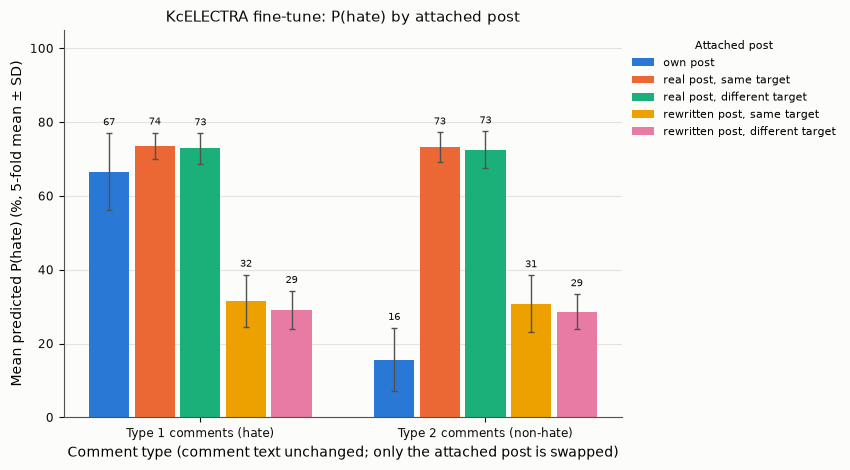

저장: figures/project_h2_plus_effects.png (300 dpi)


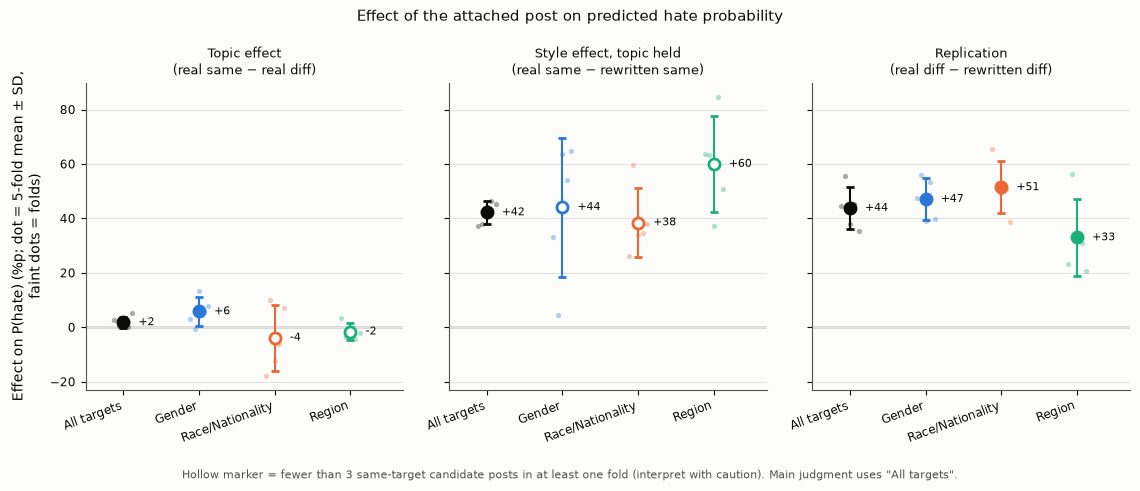

In [14]:
import matplotlib.pyplot as plt

FIG_DIR = PROJECT_ROOT / 'figures'
SURFACE, INK, MUTED, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3dd'
COND_COLOR = {'own': '#2a78d6', 'real_same': '#eb6834', 'real_diff': '#1baf7a', 'rew_topic': '#eda100', 'rew_diff': '#e87ba4'}
COND_LABEL = {'own': 'own post', 'real_same': 'real post, same target', 'real_diff': 'real post, different target',
              'rew_topic': 'rewritten post, same target', 'rew_diff': 'rewritten post, different target'}
EFF_EN = {'주제 효과': 'Topic effect\n(real same − real diff)', '주제 통제 겉모습 효과': 'Style effect, topic held\n(real same − rewritten same)',
          '재현 확인': 'Replication\n(real diff − rewritten diff)'}
GROUP_COLOR = {'All': INK, '성별': '#2a78d6', '인종·국적': '#eb6834', '지역': '#1baf7a'}
GROUP_EN = {'All': 'All targets', '성별': 'Gender', '인종·국적': 'Race/Nationality', '지역': 'Region'}


def style_ax(ax):
    ax.set_facecolor(SURFACE)
    for side in ('top', 'right'):
        ax.spines[side].set_visible(False)
    for side in ('left', 'bottom'):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=INK, labelsize=8.5)
    ax.grid(axis='y', color=GRID, linewidth=0.8, zorder=0)


def save(fig, name):
    fig.savefig(FIG_DIR / f'{name}.png', dpi=300, bbox_inches='tight', facecolor=SURFACE)
    print(f"저장: figures/{name}.png (300 dpi)")


# (1) 조건별 평균 혐오 확률
fig, ax = plt.subplots(figsize=(8.6, 4.8), facecolor=SURFACE)
style_ax(ax)
w = 0.16
for i, c in enumerate(COND_ORDER):
    for j, ty in enumerate((1, 2)):
        s = row[row['Type'] == ty].groupby('fold')[f'p_{c}'].mean()
        x = j + (i - 2) * w
        ax.bar(x, s.mean(), w * 0.88, yerr=s.std(ddof=1), color=COND_COLOR[c], label=COND_LABEL[c] if j == 0 else None,
               error_kw=dict(ecolor=MUTED, elinewidth=1, capsize=2.5), zorder=2)
        ax.text(x, s.mean() + s.std(ddof=1) + 1.5, f"{s.mean():.0f}", ha='center', va='bottom', fontsize=7.5, color=INK)
ax.set_xticks([0, 1])
ax.set_xticklabels(['Type 1 comments (hate)', 'Type 2 comments (non-hate)'])
ax.set_ylim(0, 105)
ax.set_xlabel('Comment type (comment text unchanged; only the attached post is swapped)')
ax.set_ylabel('Mean predicted P(hate) (%, 5-fold mean ± SD)')
ax.set_title('KcELECTRA fine-tune: P(hate) by attached post', fontsize=11, color=INK)
ax.legend(title='Attached post', frameon=False, fontsize=8, title_fontsize=8, loc='upper left', bbox_to_anchor=(1.0, 1.0))
fig.tight_layout()
save(fig, 'project_h2_plus_conditions')
plt.show()

# (2) 효과 크기: 전체 + 대상별, fold 점
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4.6), sharey=True, facecolor=SURFACE)
groups = ['All', '성별', '인종·국적', '지역']
for ax, (k, (a, b)) in zip(axes, COMPARE.items()):
    style_ax(ax)
    ax.axhline(0, color=MUTED, linewidth=1, zorder=1)
    for gi, g in enumerate(groups):
        sub = row if g == 'All' else row[row['target'] == EN[g]]
        pf, _ = effect(sub, a, b)
        pf = pf.dropna()
        hollow = g != 'All' and few[(k, g)]
        ax.scatter(np.full(len(pf), gi) + np.linspace(-0.12, 0.12, len(pf)), pf, s=14, color=GROUP_COLOR[g], alpha=0.35, zorder=2, linewidths=0)
        ax.errorbar(gi, pf.mean(), yerr=pf.std(ddof=1), fmt='o', ms=8, color=GROUP_COLOR[g],
                    mfc=SURFACE if hollow else GROUP_COLOR[g], mew=2, elinewidth=1.5, capsize=3, zorder=3)
        ax.text(gi + 0.2, pf.mean(), f"{pf.mean():+.0f}", va='center', fontsize=8, color=INK)
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels([GROUP_EN[g] for g in groups], rotation=20, ha='right')
    ax.set_xlim(-0.5, len(groups) - 0.3)
    ax.set_title(EFF_EN[k], fontsize=9.5, color=INK)
axes[0].set_ylabel('Effect on P(hate) (%p; dot = 5-fold mean ± SD,\nfaint dots = folds)')
fig.text(0.5, -0.04, 'Hollow marker = fewer than 3 same-target candidate posts in at least one fold (interpret with caution). '
         'Main judgment uses "All targets".', ha='center', fontsize=8, color=MUTED)
fig.suptitle('Effect of the attached post on predicted hate probability', fontsize=11, color=INK)
fig.tight_layout()
save(fig, 'project_h2_plus_effects')
plt.show()

**그림 해석**
- 실제 글이 붙으면 같은 대상이든 다른 대상이든 약 73%, 새로 쓴 글이면 약 30%다. 대상보다 실제 글인지가 결과를 갈랐다.
- 주제 효과 +2%p, 겉모습 효과 +42%p, 재현 확인 +44%p.

---
## 6. 사후 분석 — 바꿔 넣은 조합은 정말 혐오인가
5절 결과를 본 뒤 추가했다. 남의 실제 글이 붙으면 실제로 혐오일 수도 있으므로, Claude가 정답을 대신 판정한다.
- 판정자: 이 분석과 분리된 Claude(서브 에이전트). 조건·정답·데이터 구조를 모르고, 원본과 바꿔 넣은 항목을 섞어 받는다.
- 샘플: ① 원본 150개(Type 1·2 짝 50쌍 + Type 3 50개) ② 바꿔 넣은 조합 200개(조건당 50개)
- 통과 기준: ①에서 macro-F1 ≥ 0.80, 짝 정답률 ≥ 0.6
- 사람 확인은 하지 않는다(팀 결정). 조건당 50개라 오차가 약 ±14%p이므로 큰 차이만 본다.

**판정 지시문**
> 다음은 온라인 게시글 요약(글)과 그 글에 달린 댓글의 목록이다. 각 항목마다 글과 댓글을 함께 읽고, 댓글이 혐오 표현인지 판단하라.
> 혐오 표현: 성별, 장애, 인종·국적, 지역, 연령 등 특정 집단이나 그 구성원을 그 집단이라는 이유로 비하·조롱·공격하거나, 차별·혐오를 부추기는 표현. 댓글만으로는 뜻이 분명하지 않으면 글의 맥락에서 댓글이 무엇을 가리키는지 보고 판단한다.
> 각 항목에 1(혐오) 또는 0(비혐오)을 매긴다. 항목마다 직접 읽고 판단하며, 키워드 규칙이나 코드로 일괄 분류하지 않는다.

| 파일 | 내용 |
|---|---|
| `data/h2_claude_label_input.csv` | 판정 입력: item_id, 글, 댓글 (로컬, Git 제외) |
| `results/h2_claude_label_compare.csv` | 항목별 출처, 데이터셋 정답, Claude 판정, 세 모델 예측 (비교용) |

In [15]:
LABEL_INPUT = PROJECT_ROOT / 'data' / 'h2_claude_label_input.csv'
LABEL_OUT = PROJECT_ROOT / 'results' / 'h2_claude_labels.csv'   # 서브 에이전트 판정 원본 (처음 한 번만 사용, 판정은 비교 파일에 보관)
COMPARE_PATH = PROJECT_ROOT / 'results' / 'h2_claude_label_compare.csv'
COND4 = ['real_same', 'real_diff', 'rew_topic', 'rew_diff']

if True:   # 샘플은 seed로 고정돼 매번 같은 항목이 만들어진다 (6-1에서 저장된 판정과 대조)
    ctxid = lambda ix: 'ctx_' + raw.set_index('Index').loc[ix, 'Context'].map(first_idx).astype(str).to_numpy()
    own_p = preds[preds['variant'] == 'own'].set_index('Index')['p_hate']
    # ① 원본: 같은 댓글의 Type 1·2 짝 50쌍 + Type 3 50개
    pairs = (raw[raw['Type'] == 1][['Set', 'Comment', 'Index']]
             .merge(raw[raw['Type'] == 2][['Set', 'Comment', 'Index']], on=['Set', 'Comment'], suffixes=('_1', '_2'))
             .drop_duplicates('Index_1').drop_duplicates('Index_2').sample(50, random_state=SEED).reset_index(drop=True))
    o12 = pd.concat([pd.DataFrame({'Index': pairs['Index_1'], 'pair_id': pairs.index}),
                     pd.DataFrame({'Index': pairs['Index_2'], 'pair_id': pairs.index})])
    o3 = pd.DataFrame({'Index': raw[raw['Type'] == 3].sample(50, random_state=SEED)['Index'].to_numpy(), 'pair_id': np.nan})
    orig = pd.concat([o12, o3], ignore_index=True)
    r = raw.set_index('Index').loc[orig['Index']]
    orig = orig.assign(kind='원본', Type=r['Type'].to_numpy(), condition='own', fold=orig['Index'].map(FOLD_OF),
                       target=None, context_id=ctxid(orig['Index']), gold=r['Hate speech'].to_numpy(),
                       model_p_hate=own_p.loc[orig['Index']].to_numpy(), Comment=r['Comment'].to_numpy(),
                       Context=r['Context'].to_numpy())
    # ② 바꿔 넣은 조합: 조건마다 fold당 10개, draw 0
    s0 = preds[(preds['draw'] == 0) & (preds['variant'].isin(COND4))].merge(use[['Index', 'Type', 'target']], on='Index')
    sw = s0.groupby(['variant', 'fold']).sample(10, random_state=SEED).reset_index(drop=True)
    sw = sw.assign(kind='바꿔 넣음', condition=sw['variant'], pair_id=np.nan, gold=np.nan, model_p_hate=sw['p_hate'],
                   target=sw['target'].map(KO), Comment=raw.set_index('Index').loc[sw['Index'], 'Comment'].to_numpy(),
                   Context=CTX_TEXT.loc[sw['context_id']].to_numpy())
    cols = ['kind', 'Index', 'Type', 'condition', 'fold', 'target', 'context_id', 'pair_id', 'gold', 'model_p_hate', 'Context', 'Comment']
    items = pd.concat([orig[cols], sw[cols]], ignore_index=True).sample(frac=1, random_state=SEED).reset_index(drop=True)
    items.insert(0, 'item_id', [f'item_{i:03d}' for i in range(1, len(items) + 1)])
    if not LABEL_INPUT.exists():
        items[['item_id', 'Context', 'Comment']].rename(columns={'Context': '글', 'Comment': '댓글'}).to_csv(LABEL_INPUT, index=False, encoding='utf-8-sig')
        print(f"저장: {LABEL_INPUT.relative_to(PROJECT_ROOT)} (판정 입력, Git 제외)")
    key = items.drop(columns=['Context', 'Comment'])
    print(f"판정 샘플 {len(key)}개")
print(key.groupby(['kind', 'condition']).size().to_dict())
print("② 대상 분포:", key[key['kind'] == '바꿔 넣음'].groupby('condition')['target'].value_counts().unstack(fill_value=0).to_dict('index'))

판정 샘플 350개
{('바꿔 넣음', 'real_diff'): 50, ('바꿔 넣음', 'real_same'): 50, ('바꿔 넣음', 'rew_diff'): 50, ('바꿔 넣음', 'rew_topic'): 50, ('원본', 'own'): 150}
② 대상 분포: {'real_diff': {'성별': 22, '연령': 0, '인종·국적': 11, '지역': 17}, 'real_same': {'성별': 28, '연령': 0, '인종·국적': 11, '지역': 11}, 'rew_diff': {'성별': 17, '연령': 2, '인종·국적': 8, '지역': 23}, 'rew_topic': {'성별': 21, '연령': 0, '인종·국적': 13, '지역': 16}}


### 6-1. 원본 검증 — Claude 판정을 정답 대신 쓸 수 있는가

In [16]:
from sklearn.metrics import accuracy_score, cohen_kappa_score

# Claude 판정은 비교 파일에 보관한다 (처음 한 번은 서브 에이전트가 쓴 판정 파일에서 읽음)
if COMPARE_PATH.exists():
    saved = pd.read_csv(COMPARE_PATH)
    chk_cols = ['item_id', 'Index', 'condition', 'context_id']
    assert saved[chk_cols].astype(str).equals(key[chk_cols].astype(str)), '저장된 판정과 샘플 항목이 다름'
    lab = saved[['item_id', 'claude_label']]
else:
    lab = pd.read_csv(LABEL_OUT).rename(columns={'label': 'claude_label'})
cmp = key.merge(lab, on='item_id', how='left')
assert cmp['claude_label'].isin([0, 1]).all() and len(cmp) == len(key), '판정이 빠졌거나 0/1이 아님'
cmp['model_pred'] = (cmp['model_p_hate'] > 0.5).astype(int)
cmp['Claude=정답'] = np.where(cmp['gold'].notna(), (cmp['claude_label'] == cmp['gold']).astype(int), np.nan)
cmp['모델=정답'] = np.where(cmp['gold'].notna(), (cmp['model_pred'] == cmp['gold']).astype(int), np.nan)
cmp['모델=Claude'] = (cmp['model_pred'] == cmp['claude_label']).astype(int)
cmp.to_csv(COMPARE_PATH, index=False, encoding='utf-8-sig')
print(f"저장: {COMPARE_PATH.relative_to(PROJECT_ROOT)} ({len(cmp)}행) — 항목별 데이터셋 정답·Claude 판정·모델 예측 비교용")

o = cmp[cmp['kind'] == '원본'].copy()
o['gold'] = o['gold'].astype(int)
def pair_acc(df, col):
    p = df[df['pair_id'].notna()]
    return p.groupby('pair_id').apply(lambda g: bool((g[col] == g['gold']).all()), include_groups=False).mean()
val = pd.DataFrame({
    'Claude 판정': [f1_score(o['gold'], o['claude_label'], average='macro'), accuracy_score(o['gold'], o['claude_label']),
                  cohen_kappa_score(o['gold'], o['claude_label']), pair_acc(o, 'claude_label')],
    '모델(KcELECTRA, 참고)': [f1_score(o['gold'], o['model_pred'], average='macro'), accuracy_score(o['gold'], o['model_pred']),
                         cohen_kappa_score(o['gold'], o['model_pred']), pair_acc(o, 'model_pred')]},
    index=['macro-F1', '정확도', 'Cohen κ', '짝 정답률 (Type 1·2 50쌍)']).round(3)
print("[원본 150개 — 데이터셋 정답과 비교]")
display(val)
print("Type별 정확도 (Claude / 모델):",
      {f"Type {t}": f"{(g['claude_label'] == g['gold']).mean():.2f} / {(g['model_pred'] == g['gold']).mean():.2f}" for t, g in o.groupby('Type')})
PASS = val.loc['macro-F1', 'Claude 판정'] >= 0.80 and val.loc['짝 정답률 (Type 1·2 50쌍)', 'Claude 판정'] >= 0.6
print("통과 기준(macro-F1 ≥ 0.80, 짝 정답률 ≥ 0.6):", "통과 — ②의 Claude 판정을 정답 대용으로 사용" if PASS else "미달 — 정답 대용으로 쓰지 않음")

저장: results/h2_claude_label_compare.csv (350행) — 항목별 데이터셋 정답·Claude 판정·모델 예측 비교용
[원본 150개 — 데이터셋 정답과 비교]


,Claude 판정,"모델(KcELECTRA, 참고)"
macro-F1,0.875,0.831
정확도,0.893,0.853
Cohen κ,0.750,0.663
짝 정답률 (Type 1·2 50쌍),0.700,0.620


Type별 정확도 (Claude / 모델): {'Type 1': '0.76 / 0.74', 'Type 2': '0.94 / 0.86', 'Type 3': '0.98 / 0.96'}
통과 기준(macro-F1 ≥ 0.80, 짝 정답률 ≥ 0.6): 통과 — ②의 Claude 판정을 정답 대용으로 사용


### 6-2. 조건별 혐오 비율 — Claude vs 모델 (신뢰구간: Wilson 95%)

In [17]:
def wilson(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return 100 * p, 100 * (c - h), 100 * (c + h)

sw = cmp[cmp['kind'] == '바꿔 넣음']
rows_ = []
for name, g in [('원본 글 + Type 1 댓글', o[o['Type'] == 1]), ('원본 글 + Type 2 댓글', o[o['Type'] == 2])] + \
               [(c, sw[sw['condition'] == c]) for c in COND4]:
    k, n = int(g['claude_label'].sum()), len(g)
    p, lo, hi = wilson(k, n)
    rows_.append({'조건': name, 'n': n,
                  '데이터셋 정답 혐오(%)': f"{100 * g['gold'].mean():.0f}" if g['gold'].notna().all() else '—',
                  'Claude 혐오(%) [95% CI]': f"{p:.0f} [{lo:.0f}, {hi:.0f}]",
                  '모델 평균 확률(%)': f"{100 * g['model_p_hate'].mean():.0f}", '모델 혐오 판정(%)': f"{100 * g['model_pred'].mean():.0f}",
                  '모델-Claude 일치(%)': f"{100 * g['모델=Claude'].mean():.0f}"})
display(pd.DataFrame(rows_).set_index('조건'))

def diff(a, b, col='claude_label', scale=100):
    ga, gb = sw[sw['condition'] == a][col], sw[sw['condition'] == b][col]
    d = scale * (ga.mean() - gb.mean())
    se = scale * np.sqrt(ga.var(ddof=1) / len(ga) + gb.var(ddof=1) / len(gb))
    return f"{d:+.0f} [{d - 1.96 * se:+.0f}, {d + 1.96 * se:+.0f}]"
eff = pd.DataFrame({k: {'Claude 기준 혐오 비율 차이 (%p) [95% CI]': diff(a, b),
                        '모델 평균 확률 차이 (%p, 같은 항목)': diff(a, b, 'model_p_hate'),
                        '모델 혐오 판정 비율 차이 (%p, 같은 항목)': diff(a, b, 'model_pred')} for k, (a, b) in COMPARE.items()}).T
print("[5절 세 효과를 같은 200개 항목에서 Claude 기준과 모델 기준으로 비교]")
display(eff)

,n,데이터셋 정답 혐오(%),Claude 혐오(%) [95% CI],모델 평균 확률(%),모델 혐오 판정(%),모델-Claude 일치(%)
조건,,,,,,
원본 글 + Type 1 댓글,50,100,"76 [63, 86]",74,74,54
원본 글 + Type 2 댓글,50,0,"6 [2, 16]",16,14,80
real_same,50,—,"22 [13, 35]",70,72,42
real_diff,50,—,"36 [24, 50]",70,72,52
rew_topic,50,—,"16 [8, 29]",32,36,60
rew_diff,50,—,"14 [7, 26]",35,32,66


[5절 세 효과를 같은 200개 항목에서 Claude 기준과 모델 기준으로 비교]


,Claude 기준 혐오 비율 차이 (%p) [95% CI],"모델 평균 확률 차이 (%p, 같은 항목)","모델 혐오 판정 비율 차이 (%p, 같은 항목)"
주제 효과,"-14 [-32, +4]","+0 [-15, +16]","+0 [-18, +18]"
주제 통제 겉모습 효과,"+6 [-9, +21]","+38 [+23, +53]","+36 [+18, +54]"
재현 확인,"+22 [+5, +39]","+35 [+19, +51]","+40 [+22, +58]"


In [18]:
# 참고: Claude 판정의 민감도·특이도(원본 기준)로 보정한 혐오 비율 (Rogan–Gladen, 사후 참고용)
sens = o.loc[o['gold'] == 1, 'claude_label'].mean()
spec = 1 - o.loc[o['gold'] == 0, 'claude_label'].mean()
adj = {c: float(np.clip((sw.loc[sw['condition'] == c, 'claude_label'].mean() + spec - 1) / (sens + spec - 1), 0, 1) * 100) for c in COND4}
print(f"Claude 민감도 {sens:.2f}, 특이도 {spec:.2f} → 보정 혐오 비율(%):", {k: round(v) for k, v in adj.items()})

Claude 민감도 0.76, 특이도 0.96 → 보정 혐오 비율(%): {'real_same': 25, 'real_diff': 44, 'rew_topic': 17, 'rew_diff': 14}


### 6-3. 그림 — Claude 판정 주요 수치

저장: figures/project_h2_plus_claude.png (300 dpi)

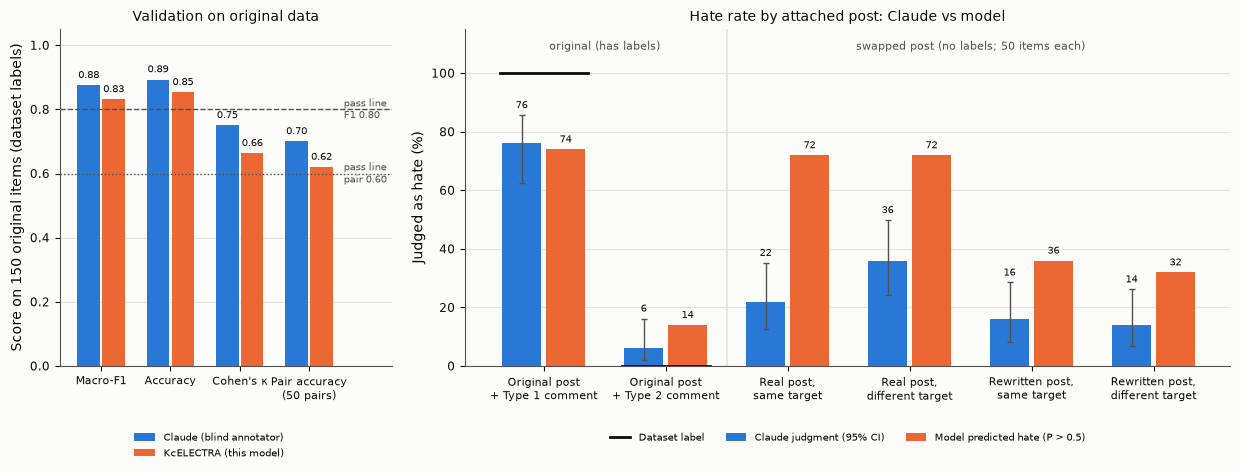

In [19]:
C_CLAUDE, C_MODEL = '#2a78d6', '#eb6834'
fig, (axL, axR) = plt.subplots(1, 2, figsize=(12.5, 4.9), facecolor=SURFACE, gridspec_kw={'width_ratios': [1, 2.3]})

# (왼쪽) 원본 150개 검증
style_ax(axL)
metrics = ['macro-F1', '정확도', 'Cohen κ', '짝 정답률 (Type 1·2 50쌍)']
labels = ['Macro-F1', 'Accuracy', "Cohen's κ", 'Pair accuracy\n(50 pairs)']
x, w = np.arange(len(metrics)), 0.36
for i, (col, colr, lab) in enumerate([('Claude 판정', C_CLAUDE, 'Claude (blind annotator)'), ('모델(KcELECTRA, 참고)', C_MODEL, 'KcELECTRA (this model)')]):
    v = val.loc[metrics, col].to_numpy()
    axL.bar(x + (i - 0.5) * w, v, w * 0.9, color=colr, label=lab, zorder=2)
    for xi, vi in zip(x + (i - 0.5) * w, v):
        axL.text(xi, vi + 0.015, f"{vi:.2f}", ha='center', va='bottom', fontsize=7.5, color=INK)
axL.axhline(0.80, color=MUTED, ls='--', lw=1)
axL.text(3.5, 0.80, 'pass line\nF1 0.80', fontsize=7, color=MUTED, va='center', ha='left')
axL.axhline(0.60, color=MUTED, ls=':', lw=1)
axL.text(3.5, 0.60, 'pass line\npair 0.60', fontsize=7, color=MUTED, va='center', ha='left')
axL.set_xticks(x)
axL.set_xticklabels(labels, fontsize=8)
axL.set_xlim(-0.6, 4.2)
axL.set_ylim(0, 1.05)
axL.set_ylabel('Score on 150 original items (dataset labels)')
axL.set_title('Validation on original data', fontsize=10, color=INK)
axL.legend(frameon=False, fontsize=7.5, loc='upper center', bbox_to_anchor=(0.45, -0.17), ncol=1)

# (오른쪽) 조건별 혐오 비율: Claude 판정 vs 모델 혐오 판정
style_ax(axR)
groups = [('Original post\n+ Type 1 comment', o[o['Type'] == 1]), ('Original post\n+ Type 2 comment', o[o['Type'] == 2])] + \
         [(n_, sw[sw['condition'] == c]) for n_, c in [('Real post,\nsame target', 'real_same'), ('Real post,\ndifferent target', 'real_diff'),
                                                     ('Rewritten post,\nsame target', 'rew_topic'), ('Rewritten post,\ndifferent target', 'rew_diff')]]
x = np.arange(len(groups))
for gi, (name, g) in enumerate(groups):
    p, lo, hi = wilson(int(g['claude_label'].sum()), len(g))
    axR.bar(gi - w / 2, p, w * 0.9, yerr=[[p - lo], [hi - p]], color=C_CLAUDE, error_kw=dict(ecolor=MUTED, elinewidth=1, capsize=2.5),
            label='Claude judgment (95% CI)' if gi == 0 else None, zorder=2)
    m = 100 * g['model_pred'].mean()
    axR.bar(gi + w / 2, m, w * 0.9, color=C_MODEL, label='Model predicted hate (P > 0.5)' if gi == 0 else None, zorder=2)
    axR.text(gi - w / 2, hi + 1.5, f"{p:.0f}", ha='center', va='bottom', fontsize=7.5, color=INK)
    axR.text(gi + w / 2, m + 1.5, f"{m:.0f}", ha='center', va='bottom', fontsize=7.5, color=INK)
    if g['gold'].notna().all():
        axR.plot([gi - w, gi + w], [100 * g['gold'].mean()] * 2, color=INK, lw=2, zorder=3,
                 label='Dataset label' if gi == 0 else None)
axR.axvline(1.5, color=GRID, lw=1.2)
axR.text(0.5, 108, 'original (has labels)', ha='center', fontsize=8, color=MUTED)
axR.text(3.5, 108, 'swapped post (no labels; 50 items each)', ha='center', fontsize=8, color=MUTED)
axR.set_xticks(x)
axR.set_xticklabels([n_ for n_, _ in groups], fontsize=8)
axR.set_ylim(0, 115)
axR.set_ylabel('Judged as hate (%)')
axR.set_title('Hate rate by attached post: Claude vs model', fontsize=10, color=INK)
axR.legend(frameon=False, fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3)
fig.tight_layout()
save(fig, 'project_h2_plus_claude')
plt.show()

**그림 해석**: 원본에서는 Claude가 정답을 대체로 따른다. 남의 글을 붙이면 Claude 기준 혐오는 14~36%인데, 모델은 실제 글이면 72%, 새로 쓴 글이면 32~36%다.

### 6-4. 해석
- Claude 판정은 통과했다(macro-F1 0.875, 짝 정답률 0.70). 다만 혐오의 24%를 놓친다.
- 남의 실제 글을 붙인 조합은 Claude 기준 22~36%만 혐오인데, 모델은 약 70%로 본다.
- 같은 대상끼리 실제 − 새로 씀: Claude +6%p(0과 구분 안 됨), 모델 +38%p.
- 다른 대상끼리는 Claude도 +22%p다. 실제 글이 붙으면 진짜 혐오가 조금 늘기도 한다.
- 한계: 판정자는 Claude 1명, 사람 확인 없음, 조건당 50개.

---
## 7. 다른 모델 확인 — KLUE-RoBERTa (사후 추가, 2026-11-18)
"실제 글에 크게 반응하는 것"이 KcELECTRA만의 문제인지 보려고, 같은 실험을 KLUE-RoBERTa로 반복한다. 설정·바꿔 넣는 글·판정 규칙은 4~5절과 같다(같은 seed라 바꿔 넣는 글도 똑같이 뽑힌다).

**판단 기준 (실행 전 고정)**
- KLUE의 겉모습 효과(같은 대상 실제 − 같은 대상 새로 씀)가 3절 규칙으로 **유의(+)이면 "KLUE도 실제 글에 반응"**, 아니면 "반응하지 않음".
- 크기는 KcELECTRA(+42.2%p)와 나란히 보고한다. 후속 연구 모델로 쓸지는 이것만으로 정하지 않고 macro-F1과 주제 효과도 함께 본다.
- 재현 확인: 원래 글 macro-F1이 기존 KLUE 0.778(`results/plm_folds.csv`)과 ±0.02 안.

In [20]:
import tempfile, time

MODEL2, REPRO2 = 'klue-roberta-base', 0.778

preds2, runs2 = load_saved(MODEL2)
if preds2 is None:
    device = plm.pick_device()
    PROGRESS2 = Path(tempfile.gettempdir()) / 'h2_plus_progress_klue.log'
    PROGRESS2.write_text('')
    print(f"{MODEL2}, seed = {SEED}, device = {device}, 학습 {len(SPLITS)}회 — 진행 로그: {PROGRESS2}")
    parts, runs2 = [], []
    for fold, train, test, *_ in SPLITS:
        extras, picks = make_variants(fold, test)
        y, pred, info = plm.finetune_one(plm.MODELS[MODEL2], train, test, 'cross', device,
                                         method='finetune', seed=SEED, extra_tests=extras)
        parts.append(pd.DataFrame({'fold': fold, 'Index': test['Index'].to_numpy(), 'variant': 'own', 'draw': 0,
                                   'context_id': '', 'y': y, 'score': info['score']}))
        for pk in picks:
            k_ = f"{pk['variant'].iloc[0]}#{pk['draw'].iloc[0]}"
            parts.append(pk.assign(fold=fold, y=extras[k_]['Hate speech'].to_numpy(), score=info['extra_score'][k_]))
        f1 = f1_score(y, (info['score'] > 0).astype(int), average='macro')
        runs2.append({'model': MODEL2, 'method': 'finetune', 'seed': SEED, 'fold': fold, 'device': device.type,
                      'train_sec': info['train_sec'], 'train_loss': info['train_loss'], 'own_macro_f1': round(f1, 6)})
        msg = f"  fold {fold}: 학습 {info['train_sec']:.0f}s, 원래 글 macro-F1 {f1:.3f}"
        print(msg)
        with open(PROGRESS2, 'a', encoding='utf-8') as fh:
            fh.write(f"{time.strftime('%H:%M:%S')} {len(runs2)}/{len(SPLITS)}{msg}\n")
    preds2 = pd.concat(parts, ignore_index=True)[['fold', 'Index', 'variant', 'draw', 'context_id', 'y', 'score']]
    preds2.insert(0, 'model', MODEL2)
    preds2['p_hate'] = 1 / (1 + np.exp(-preds2['score']))
    runs2 = pd.DataFrame(runs2)
    save_model(MODEL2, preds2, runs2)

old2 = (pd.read_csv(PROJECT_ROOT / 'results' / 'plm_folds.csv')
          .query("model == @MODEL2 and method == 'finetune' and condition == 'Context+Comment'").set_index('fold')['macro_f1'])
rep2 = runs2.set_index('fold')[['train_sec', 'own_macro_f1']].assign(**{'기존(plm_folds)': old2})
rep2['차이'] = rep2['own_macro_f1'] - rep2['기존(plm_folds)']
display(rep2.round(3))
gap2 = runs2['own_macro_f1'].mean() - REPRO2
print(f"평균 macro-F1 {runs2['own_macro_f1'].mean():.3f} (기존 {REPRO2}) → 차이 {gap2:+.3f}: "
      + ("재현됨 (±0.02 안)" if abs(gap2) <= REPRO_TOL else "기준 밖 — 해석 전에 원인 확인"))

저장된 점수를 읽음: klue-roberta-base 18,972행 (results/plm_h2_topic_preds.csv)


,train_sec,own_macro_f1,기존(plm_folds),차이
fold,,,,
0,155.9,0.824,0.791,0.033
1,198.6,0.756,0.774,-0.018
2,193.9,0.766,0.778,-0.012
3,207.9,0.809,0.761,0.048
4,198.5,0.793,0.788,0.005


평균 macro-F1 0.790 (기존 0.778) → 차이 +0.012: 재현됨 (±0.02 안)


### 7-1. KcELECTRA vs KLUE — 조건별 혐오 확률과 세 효과

In [21]:
def build_rows(pr):
    d_ = pr[pr['variant'] != 'own'].merge(use[['Index', 'Type', 'target']], on='Index')
    r_ = (d_.assign(p=d_['p_hate'] * 100).groupby(['fold', 'Index', 'Type', 'target', 'variant'])['p'].mean()
             .unstack('variant').add_prefix('p_'))
    own_ = (pr[pr['variant'] == 'own'].merge(use[['Index', 'Type', 'target']], on='Index')
               .set_index(['fold', 'Index', 'Type', 'target'])['p_hate'] * 100)
    r_['p_own'] = own_
    return r_.reset_index()

row2 = build_rows(preds2)
MODELS_CMP = {'KcELECTRA': row, 'KLUE-RoBERTa': row2}
cond_tab = {}
for mname, rw in MODELS_CMP.items():
    for ty in (1, 2):
        sub = rw[rw['Type'] == ty]
        cond_tab[(mname, f'Type {ty}')] = {c: (lambda s: f"{s.mean():.1f} ± {s.std(ddof=1):.1f}")(sub.groupby('fold')[f'p_{c}'].mean()) for c in COND_ORDER}
print("[평균 혐오 확률(%) — 5-fold 평균 ± SD]")
display(pd.DataFrame(cond_tab).T[COND_ORDER])

eff_cmp, pf_cmp = [], {}
for k, (a, b) in COMPARE.items():
    for mname, rw in MODELS_CMP.items():
        pf, n = effect(rw, a, b)
        pf_cmp[(k, mname)] = pf
        eff_cmp.append({'비교': k, '모델': mname, '행 수': n, **verdict(pf.to_numpy())})
eff_cmp = pd.DataFrame(eff_cmp).set_index(['비교', '모델'])
print("[세 효과 — 대상 합산, 3절 판정 규칙]")
display(eff_cmp)
v2 = eff_cmp.loc[('주제 통제 겉모습 효과', 'KLUE-RoBERTa'), '판정']
print("판단(7절 기준):", "KLUE도 실제 글에 반응" if v2 == '유의(+)' else "KLUE는 실제 글에 반응하지 않음",
      f"(KLUE 겉모습 효과 {eff_cmp.loc[('주제 통제 겉모습 효과', 'KLUE-RoBERTa'), '평균(%p)']}, "
      f"KcELECTRA {eff_cmp.loc[('주제 통제 겉모습 효과', 'KcELECTRA'), '평균(%p)']})")

# Claude 판정 200개 항목에서 두 모델 비교 (같은 글이 뽑혔으므로 같은 항목)
k2 = preds2[(preds2['draw'] == 0) & preds2['variant'].isin(COND4)][['Index', 'variant', 'context_id', 'p_hate']]
sw2 = sw.merge(k2.rename(columns={'variant': 'condition', 'p_hate': 'klue_p'}), on=['Index', 'condition', 'context_id'], how='left')
assert sw2['klue_p'].notna().all(), 'KLUE 예측과 항목이 맞지 않음'
cl_tab = sw2.groupby('condition').agg(n=('item_id', 'size'), Claude=('claude_label', 'mean'),
                                      KcELECTRA=('model_pred', 'mean'), KLUE=('klue_p', lambda s: (s > 0.5).mean())).reindex(COND4)
cl_tab[['Claude', 'KcELECTRA', 'KLUE']] = (cl_tab[['Claude', 'KcELECTRA', 'KLUE']] * 100).round(0)
print("[Claude 판정 200개 항목 — 혐오 비율(%): Claude 판정 vs 두 모델의 혐오 판정(> 0.5)]")
display(cl_tab)

[평균 혐오 확률(%) — 5-fold 평균 ± SD]


own   real_same   real_diff   rew_topic  \
KcELECTRA    Type 1  66.6 ± 10.4  73.6 ± 3.6  72.9 ± 4.1  31.6 ± 7.1   
             Type 2   15.7 ± 8.6  73.2 ± 4.0  72.6 ± 5.0  30.8 ± 7.7   
KLUE-RoBERTa Type 1  68.3 ± 13.8  63.6 ± 3.3  57.0 ± 4.6  25.7 ± 9.0   
             Type 2   13.1 ± 6.9  63.6 ± 4.2  57.2 ± 4.9  25.1 ± 9.2   

                       rew_diff  
KcELECTRA    Type 1  29.2 ± 5.1  
             Type 2  28.6 ± 4.7  
KLUE-RoBERTa Type 1  14.6 ± 5.6  
             Type 2  15.1 ± 4.2

[세 효과 — 대상 합산, 3절 판정 규칙]


행 수       평균(%p) >0 fold       p     판정
비교           모델                                                    
주제 효과        KcELECTRA     1272   +1.8 ± 2.1     5/5   0.116  판단 보류
             KLUE-RoBERTa  1272   +8.2 ± 2.6     5/5   0.002  유의(+)
주제 통제 겉모습 효과 KcELECTRA     1244  +42.2 ± 4.3     5/5  <0.001  유의(+)
             KLUE-RoBERTa  1244  +36.9 ± 7.5     5/5  <0.001  유의(+)
재현 확인        KcELECTRA     1360  +43.8 ± 7.8     5/5  <0.001  유의(+)
             KLUE-RoBERTa  1360  +42.2 ± 8.1     5/5  <0.001  유의(+)

판단(7절 기준): KLUE도 실제 글에 반응 (KLUE 겉모습 효과 +36.9 ± 7.5, KcELECTRA +42.2 ± 4.3)
[Claude 판정 200개 항목 — 혐오 비율(%): Claude 판정 vs 두 모델의 혐오 판정(> 0.5)]


,n,Claude,KcELECTRA,KLUE
condition,,,,
real_same,50,22.0,72.0,64.0
real_diff,50,36.0,72.0,52.0
rew_topic,50,16.0,36.0,24.0
rew_diff,50,14.0,32.0,12.0


### 7-2. 해석
- **판단(7절 기준): KLUE도 실제 글에 반응한다.** 겉모습 효과 +36.9%p(유의), KcELECTRA +42.2%p와 비슷한 크기다. 재현 확인도 +42.2%p로 같다.
- KLUE는 **주제 효과도 유의**하다(+8.2%p, 5/5 fold, p = 0.002). 같은 대상의 실제 글을 붙이면 조금 더 혐오로 본다. 맥락의 관계를 KcELECTRA(+1.8%p)보다는 조금 더 쓴다.
- 그래도 크기는 겉모습 효과(+37%p)가 주제 효과(+8%p)의 약 4.5배다. 3절 해석표로는 "둘 다 사용 → 크기 비교"이며, 실제 글인지가 훨씬 크게 작용한다.
- Claude 판정 200개 항목에서 KLUE는 KcELECTRA보다 Claude에 가깝지만(예: 다른 대상 실제 글 52% vs 72%, Claude 36%), 실제 글 조합은 여전히 높게 본다(52~64%, Claude 22~36%).
- **의미**: "실제 글이면 혐오"로 기우는 경향은 특정 모델이 아니라 **데이터 구성(새로 쓴 글 = 모두 비혐오)에서 오는 공통 문제**일 가능성이 크다. 모델만 KLUE로 바꾸는 것으로는 해결되지 않는다.
- 한계: 학습 seed 1개. KLUE 재현은 평균 기준 통과(0.790, 기존 0.778)지만 fold별 차이가 최대 0.048로 KcELECTRA보다 크다.

---
## 8. 다른 모델 확인 — 다국어 BERT (mBERT, 사후 추가, 2026-11-18)
한국어 특화가 아닌 모델도 같은 경향인지 본다. 모델은 `bert-base-multilingual-cased`(104개 언어, `model/`에 받아 둠). 설정·바꿔 넣는 글·판정 규칙은 7절과 같다.

**판단 기준 (실행 전 고정)**: 겉모습 효과가 유의(+)이면 "mBERT도 실제 글에 반응", 아니면 "반응하지 않음". 기존 기록이 없어 재현 확인 대신 원래 글 macro-F1을 세 모델 나란히 보고한다.

In [22]:
MODEL3 = 'bert-base-multilingual-cased'

preds3, runs3 = load_saved(MODEL3)
if preds3 is None:
    device = plm.pick_device()
    PROGRESS3 = Path(tempfile.gettempdir()) / 'h2_plus_progress_mbert.log'
    PROGRESS3.write_text('')
    print(f"{MODEL3}, seed = {SEED}, device = {device}, 학습 {len(SPLITS)}회 — 진행 로그: {PROGRESS3}")
    parts, runs3 = [], []
    for fold, train, test, *_ in SPLITS:
        extras, picks = make_variants(fold, test)
        y, pred, info = plm.finetune_one(PROJECT_ROOT / 'model' / MODEL3, train, test, 'cross', device,
                                         method='finetune', seed=SEED, extra_tests=extras)
        parts.append(pd.DataFrame({'fold': fold, 'Index': test['Index'].to_numpy(), 'variant': 'own', 'draw': 0,
                                   'context_id': '', 'y': y, 'score': info['score']}))
        for pk in picks:
            k_ = f"{pk['variant'].iloc[0]}#{pk['draw'].iloc[0]}"
            parts.append(pk.assign(fold=fold, y=extras[k_]['Hate speech'].to_numpy(), score=info['extra_score'][k_]))
        f1 = f1_score(y, (info['score'] > 0).astype(int), average='macro')
        runs3.append({'model': MODEL3, 'method': 'finetune', 'seed': SEED, 'fold': fold, 'device': device.type,
                      'train_sec': info['train_sec'], 'train_loss': info['train_loss'], 'own_macro_f1': round(f1, 6)})
        msg = f"  fold {fold}: 학습 {info['train_sec']:.0f}s, 원래 글 macro-F1 {f1:.3f}"
        print(msg)
        with open(PROGRESS3, 'a', encoding='utf-8') as fh:
            fh.write(f"{time.strftime('%H:%M:%S')} {len(runs3)}/{len(SPLITS)}{msg}\n")
    preds3 = pd.concat(parts, ignore_index=True)[['fold', 'Index', 'variant', 'draw', 'context_id', 'y', 'score']]
    preds3.insert(0, 'model', MODEL3)
    preds3['p_hate'] = 1 / (1 + np.exp(-preds3['score']))
    runs3 = pd.DataFrame(runs3)
    save_model(MODEL3, preds3, runs3)

f1_tab = pd.DataFrame({'KcELECTRA': runs.set_index('fold')['own_macro_f1'], 'KLUE-RoBERTa': runs2.set_index('fold')['own_macro_f1'],
                       'mBERT': runs3.set_index('fold')['own_macro_f1']})
f1_tab.loc['평균'] = f1_tab.mean()
print("[원래 글 macro-F1 — 세 모델]")
display(f1_tab.round(3))

저장된 점수를 읽음: bert-base-multilingual-cased 18,972행 (results/plm_h2_topic_preds.csv)
[원래 글 macro-F1 — 세 모델]


,KcELECTRA,KLUE-RoBERTa,mBERT
fold,,,
0,0.773,0.824,0.746
1,0.761,0.756,0.709
2,0.794,0.766,0.719
3,0.887,0.809,0.751
4,0.826,0.793,0.796
평균,0.809,0.790,0.744


### 8-1. 세 모델 비교

[세 효과 — 대상 합산, 3절 판정 규칙]


평균(%p) >0 fold       p     판정
비교           모델                                               
주제 효과        KcELECTRA       +1.8 ± 2.1     5/5   0.116  판단 보류
             KLUE-RoBERTa    +8.2 ± 2.6     5/5   0.002  유의(+)
             mBERT           +8.4 ± 6.1     5/5   0.037  유의(+)
주제 통제 겉모습 효과 KcELECTRA      +42.2 ± 4.3     5/5  <0.001  유의(+)
             KLUE-RoBERTa   +36.9 ± 7.5     5/5  <0.001  유의(+)
             mBERT         +25.2 ± 10.5     5/5   0.006  유의(+)
재현 확인        KcELECTRA      +43.8 ± 7.8     5/5  <0.001  유의(+)
             KLUE-RoBERTa   +42.2 ± 8.1     5/5  <0.001  유의(+)
             mBERT          +33.2 ± 9.4     5/5   0.001  유의(+)

판단(8절 기준): mBERT도 실제 글에 반응 (mBERT 겉모습 효과 +25.2 ± 10.5)


[Claude 판정 200개 항목 — 혐오 비율(%)]


,Claude,KcELECTRA,KLUE,mBERT
condition,,,,
real_same,22.0,72.0,64.0,56.0
real_diff,36.0,72.0,52.0,52.0
rew_topic,16.0,36.0,24.0,28.0
rew_diff,14.0,32.0,12.0,22.0


저장: results/h2_claude_label_compare.csv — 항목 350개, 데이터셋 정답·Claude·세 모델 예측
저장: figures/project_h2_plus_models.png (300 dpi)


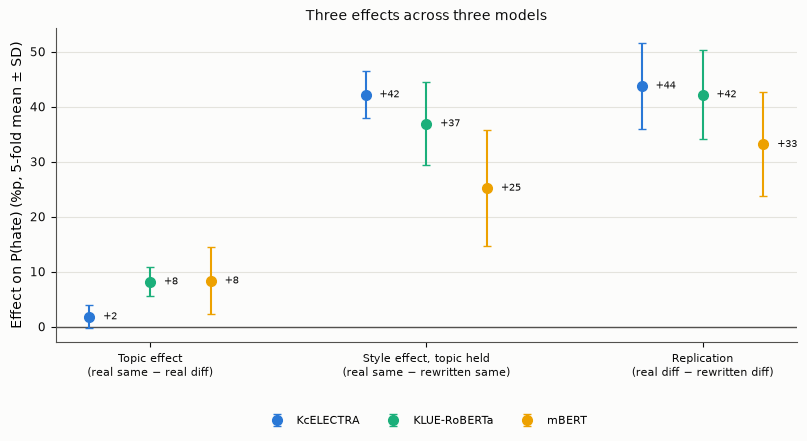

In [23]:
row3 = build_rows(preds3)
MODELS3 = {'KcELECTRA': row, 'KLUE-RoBERTa': row2, 'mBERT': row3}
eff3, pf3 = [], {}
for k, (a, b) in COMPARE.items():
    for mname, rw in MODELS3.items():
        pf, n = effect(rw, a, b)
        pf3[(k, mname)] = pf
        eff3.append({'비교': k, '모델': mname, **verdict(pf.to_numpy())})
eff3 = pd.DataFrame(eff3).set_index(['비교', '모델'])
print("[세 효과 — 대상 합산, 3절 판정 규칙]")
display(eff3)
v3 = eff3.loc[('주제 통제 겉모습 효과', 'mBERT'), '판정']
print("판단(8절 기준):", "mBERT도 실제 글에 반응" if v3 == '유의(+)' else "mBERT는 실제 글에 반응하지 않음",
      f"(mBERT 겉모습 효과 {eff3.loc[('주제 통제 겉모습 효과', 'mBERT'), '평균(%p)']})")

k3 = preds3[(preds3['draw'] == 0) & preds3['variant'].isin(COND4)][['Index', 'variant', 'context_id', 'p_hate']]
sw3 = sw2.merge(k3.rename(columns={'variant': 'condition', 'p_hate': 'mbert_p'}), on=['Index', 'condition', 'context_id'], how='left')
assert sw3['mbert_p'].notna().all()
cl3 = sw3.groupby('condition').agg(Claude=('claude_label', 'mean'), KcELECTRA=('model_pred', 'mean'),
                                   KLUE=('klue_p', lambda s: (s > 0.5).mean()), mBERT=('mbert_p', lambda s: (s > 0.5).mean())).reindex(COND4)
print("[Claude 판정 200개 항목 — 혐오 비율(%)]")
display((cl3 * 100).round(0))

# 비교 파일에 KLUE·mBERT 예측을 추가해 다시 저장 (원본 항목은 원래 글 예측)
full = cmp.rename(columns={'model_p_hate': 'kcelectra_p_hate', 'model_pred': 'kcelectra_pred',
                           '모델=정답': 'KcELECTRA=정답', '모델=Claude': 'KcELECTRA=Claude'})
for name, pr in [('klue', preds2), ('mbert', preds3)]:
    swp = (pr[(pr['draw'] == 0) & pr['variant'].isin(COND4)][['Index', 'variant', 'context_id', 'p_hate']]
             .rename(columns={'variant': 'condition', 'p_hate': f'{name}_p_hate'}))
    full = full.merge(swp, on=['Index', 'condition', 'context_id'], how='left')
    own_ = pr[pr['variant'] == 'own'].set_index('Index')['p_hate']
    m_ = full['kind'] == '원본'
    full.loc[m_, f'{name}_p_hate'] = own_.loc[full.loc[m_, 'Index']].to_numpy()
    assert full[f'{name}_p_hate'].notna().all()
    full[f'{name}_pred'] = (full[f'{name}_p_hate'] > 0.5).astype(int)
full.to_csv(COMPARE_PATH, index=False, encoding='utf-8-sig')
print(f"저장: {COMPARE_PATH.relative_to(PROJECT_ROOT)} — 항목 {len(full)}개, 데이터셋 정답·Claude·세 모델 예측")

# 그림: 세 모델의 세 효과
fig, ax = plt.subplots(figsize=(8.2, 4.6), facecolor=SURFACE)
style_ax(ax)
ax.axhline(0, color=MUTED, lw=1)
xb = np.arange(len(COMPARE))
for i, (mname, colr) in enumerate([('KcELECTRA', '#2a78d6'), ('KLUE-RoBERTa', '#1baf7a'), ('mBERT', '#eda100')]):
    pfs = [pf3[(k, mname)] for k in COMPARE]
    mu = [p_.mean() for p_ in pfs]; sd = [p_.std(ddof=1) for p_ in pfs]
    xs = xb + (i - 1) * 0.22
    ax.errorbar(xs, mu, yerr=sd, fmt='o', ms=7, color=colr, capsize=3, label=mname, zorder=3)
    for xi, m_ in zip(xs, mu):
        ax.text(xi + 0.05, m_, f"{m_:+.0f}", va='center', fontsize=7.5, color=INK)
ax.set_xticks(xb)
ax.set_xticklabels(['Topic effect\n(real same − real diff)', 'Style effect, topic held\n(real same − rewritten same)', 'Replication\n(real diff − rewritten diff)'], fontsize=8)
ax.set_ylabel('Effect on P(hate) (%p, 5-fold mean ± SD)')
ax.set_title('Three effects across three models', fontsize=10, color=INK)
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.2), ncol=3)
fig.tight_layout()
save(fig, 'project_h2_plus_models')
plt.show()

In [24]:
# Claude 판정 비율 (조건 × Type) — 아래 붙인 글별 그림에서 사용
cl_items = pd.concat([o.assign(condition='own'), sw])            # 6절 판정 항목 (원본 Type 1·2 + 바꿔 넣은 조합)
cl_items = cl_items[cl_items['Type'].isin([1, 2])]
cl_rate = cl_items.groupby(['condition', 'Type'])['claude_label'].agg(['mean', 'size'])
print("[Claude 판정 비율(%)과 항목 수 — 조건 × Type]")
display(cl_rate.assign(mean=lambda d: (d['mean'] * 100).round(0)).unstack('Type'))

[Claude 판정 비율(%)과 항목 수 — 조건 × Type]


mean       size    
Type          1     2    1   2
condition                     
own        76.0   6.0   50  50
real_diff  41.0  28.0   32  18
real_same  14.0  28.0   21  29
rew_diff   12.0  15.0   24  26
rew_topic  18.0  14.0   22  28

저장: figures/project_h2_plus_conditions_by_post.png (300 dpi)


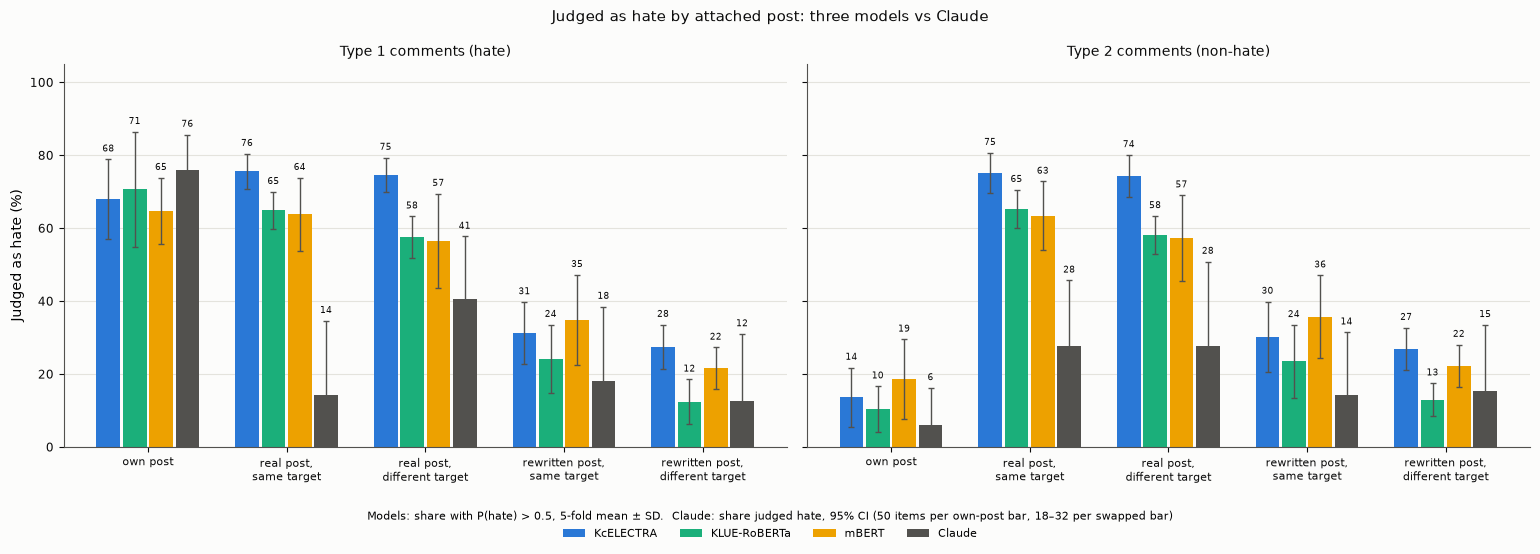

In [25]:
# 그림: 붙인 글별로 세 모델과 Claude의 혐오 판정 비율 비교 (단위: 혐오로 판정한 비율, %)
def hate_rate_rows(pr):
    d_ = pr.merge(use[['Index', 'Type']], on='Index')
    d_ = d_.assign(h=(d_['score'] > 0).astype(float) * 100)
    r_ = d_.groupby(['fold', 'Index', 'Type', 'variant'])['h'].mean().reset_index()   # 행마다 3번 뽑기 평균
    return r_.groupby(['variant', 'Type', 'fold'])['h'].mean()                        # fold별 평균

HR = {'KcELECTRA': hate_rate_rows(preds), 'KLUE-RoBERTa': hate_rate_rows(preds2), 'mBERT': hate_rate_rows(preds3)}
BAR_COLOR = {'KcELECTRA': '#2a78d6', 'KLUE-RoBERTa': '#1baf7a', 'mBERT': '#eda100', 'Claude': '#52514e'}
POST_LABEL = ['own post', 'real post,\nsame target', 'real post,\ndifferent target', 'rewritten post,\nsame target', 'rewritten post,\ndifferent target']
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.0), sharey=True, facecolor=SURFACE)
w = 0.19
for ax, ty in zip(axes, (1, 2)):
    style_ax(ax)
    for ci, c in enumerate(COND_ORDER):
        for bi, name in enumerate(['KcELECTRA', 'KLUE-RoBERTa', 'mBERT', 'Claude']):
            x = ci + (bi - 1.5) * w
            if name == 'Claude':
                k_, n_ = int(round(cl_rate.loc[(c, ty), 'mean'] * cl_rate.loc[(c, ty), 'size'])), int(cl_rate.loc[(c, ty), 'size'])
                m_, lo, hi = wilson(k_, n_)
                err = [[m_ - lo], [hi - m_]]
            else:
                s = HR[name].loc[(c, ty)]
                m_, err = s.mean(), s.std(ddof=1)
            ax.bar(x, m_, w * 0.9, yerr=err, color=BAR_COLOR[name], label=name if (ci == 0 and ty == 1) else None,
                   error_kw=dict(ecolor=MUTED, elinewidth=1, capsize=2), zorder=2)
            top = m_ + (err[1][0] if name == 'Claude' else err)
            ax.text(x, top + 1.5, f"{m_:.0f}", ha='center', va='bottom', fontsize=6.8, color=INK)
    ax.set_xticks(range(len(COND_ORDER)))
    ax.set_xticklabels(POST_LABEL, fontsize=8)
    ax.set_ylim(0, 105)
    ax.set_title(f"Type {ty} comments ({'hate' if ty == 1 else 'non-hate'})", fontsize=10, color=INK)
axes[0].set_ylabel('Judged as hate (%)')
fig.suptitle('Judged as hate by attached post: three models vs Claude', fontsize=11, color=INK)
fig.legend(frameon=False, fontsize=8, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.1),
           title='Models: share with P(hate) > 0.5, 5-fold mean ± SD.  Claude: share judged hate, 95% CI (50 items per own-post bar, 18–32 per swapped bar)',
           title_fontsize=8)
fig.tight_layout()
save(fig, 'project_h2_plus_conditions_by_post')
plt.show()

**그림 해석**: 원래 글에서는 세 모델과 Claude가 모두 Type 1을 높게, Type 2를 낮게 판정한다. 남의 실제 글을 붙이면 세 모델은 Type과 상관없이 절반 이상을 혐오로 판정하지만 Claude(회색)는 14~41%다. 남의 새로 쓴 글에서는 모델과 Claude의 차이가 작다.

### 8-2. 해석
- **판단(8절 기준): mBERT도 실제 글에 반응한다.** 겉모습 효과 +25.2%p(유의, 5/5 fold, p = 0.006).
- 크기는 세 모델 중 가장 작다(KcELECTRA +42, KLUE +37, mBERT +25%p). 다만 mBERT는 원래 글 성능도 가장 낮아(macro-F1 0.744, KcELECTRA 0.809, KLUE 0.790) 전체적으로 덜 배운 영향일 수 있다. 지름길을 덜 쓴다고 보기는 어렵다.
- 주제 효과는 KLUE와 비슷하게 유의하다(+8.4%p, p = 0.037).
- Claude 판정 200개 항목에서도 실제 글 조합을 52~56%로 보아, Claude(22~36%)보다 높다.
- **의미**: 한국어 특화 모델 2개와 다국어 모델 1개가 모두 실제 글에 반응했다. 이 경향은 **모델보다 데이터 구성(새로 쓴 글 = 모두 비혐오)에서 오는 공통 문제**라는 근거가 더 단단해졌다.
- 참고: mBERT 토크나이저를 불러올 때 정규식 관련 경고가 나왔지만, 토큰화 결과(평균 40토큰, 128 초과 0.4%)는 정상이었다.

---
## 9. 결론 (팀 검토용)
> 글을 바꿔 넣었을 때 Claude 판정은 원래 글과 함께일 때만 혐오가 높아, 글과 댓글의 관계를 볼 때 기대되는 모습과 일치했다. 반면 세 모델(KcELECTRA, KLUE-RoBERTa, 다국어 BERT)은 관계보다 **붙은 글이 실제 글인지**에 따라 혐오 판정이 크게 달라졌다. 이 경향은 주제(혐오 대상)를 맞춰도 그대로였다.

**근거**
1. 주 실험(KcELECTRA): 주제 효과 +1.8%p(판단 보류), 겉모습 효과 +42.2%p(유의), 재현 확인 +43.8%p(유의) → 사전 해석표로 "겉모습 가설 강화" (5절)
2. 남의 실제 글을 붙인 조합: Claude 기준 혐오 14~41%, 세 모델 57~76% (6·8절)
3. 같은 대상끼리 실제 − 새로 씀: Claude +6%p, KcELECTRA +38%p (6절)
4. KLUE(+36.9%p)·다국어 BERT(+25.2%p)도 겉모습 효과가 유의했다. 두 모델은 주제 효과도 약 +8%p로 유의해 관계를 조금 보지만, 겉모습 효과가 훨씬 크다 (7·8절)

**의미**: 중간보고의 맥락 이득(macro-F1 0.672 → 0.809)은 글과 댓글의 관계를 읽어서라기보다 실제 글과 새로 쓴 글을 가려서 얻었을 가능성이 크다. 세 모델이 모두 같은 경향이라 **모델보다 데이터 구성(새로 쓴 글 = 모두 비혐오)의 문제**로 보인다.

**주의**
- Claude는 정답 대용 기준이었지 실험 대상이 아니다. Claude가 실제로 관계를 보는지는 확인하지 않았다.
- 남의 실제 글이 붙으면 Claude 기준으로도 혐오가 조금 늘어(Type 2: 6% → 28%), 모델의 반응이 전부 오류는 아니다.
- "실제 글다운 특성"이 문체인지 사건 서술인지는 가르지 못했다.

**한계**: 글 주제는 Claude 판단(사람 일치 87%, 기준 미달) · 일부 대상은 후보 글이 적음 · 학습 seed 1개(모델 3개) · 6절은 Claude 1명 판정, 사람 확인 없음, 조건당 50개 · 6~8절은 결과를 본 뒤 추가한 분석